In [1]:
!pip install albumentations --quiet

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model, callbacks
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, Activation, Add,
    MaxPooling2D, UpSampling2D, Concatenate, Multiply, Dropout
)
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import albumentations as A
from datetime import datetime
from sklearn.metrics import confusion_matrix
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# GPU check
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

2026-02-05 13:45:59.803503: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1770299160.000163      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1770299160.057773      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1770299160.542807      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1770299160.542849      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1770299160.542852      24 computation_placer.cc:177] computation placer alr

TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
def clean_mask_from_path(mask_path, threshold=15, min_area=10):
    # Reads the mask image and cleans noise (pixels that appear black but are not strictly 0)
    # Read the file in grayscale mode
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    if mask is None:
        return None

    # THRESHOLDING: 
    # If a pixel value is below 'threshold' force it to 0.
    # This removes invisible noise caused by image compression (JPEG artifacts).
    _, binary_mask = cv2.threshold(mask, threshold, 255, cv2.THRESH_BINARY)

    # MORPHOLOGICAL CLEANING 
    # Removes isolated single pixels (salt noise) that survived thresholding
    kernel = np.ones((3,3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    # AREA FILTERING
    # Analyzes connected white regions. If a region is smaller than 'min_area',
    # it is considered noise/dust and removed, not a real fabric defect.
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)
    
    cleaned_mask = np.zeros_like(binary_mask)
    
    for i in range(1, num_labels): # 0 is background, start from 1
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cleaned_mask[labels == i] = 255 

    # Normalize to 0.0 and 1.0 (float32) for the Neural Network
    return (cleaned_mask > 0).astype(np.float32)

In [4]:
class Config:
    DATA_PATH = ""  
    
    # Image settings
    ORIG_WIDTH = 4096
    ORIG_HEIGHT = 256
    PATCH_SIZE = 256
    
    # Training settings
    BATCH_SIZE = 16  
    EPOCHS = 200     
    LEARNING_RATE = 1e-4
    
    # Data balance settings 
    PATCHES_PER_IMAGE = 16  # Number of patches to extract from each image
    DEFECT_PATCH_RATIO = 0.75  # 75% of patches will be defect-centered
    MIN_DEFECT_PIXELS = 10  # At least 500 pixels should be defect
    
    # Augmentation
    AUGMENT_PROB = 0.8
    
    MASK_THRESHOLD = 0

# Automatically find dataset path
for root, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "val" in dirs:
        Config.DATA_PATH = root
        print(f"Dataset found: {Config.DATA_PATH}")
        break

if not Config.DATA_PATH:
    print("WARNING: Dataset not found. Please check /kaggle/input")

Dataset found: /kaggle/input/aitex-dataset/aitex_dataset_processed


In [5]:
import os
import cv2
import numpy as np
import glob

def terminate_bad_files():
    """
    Scans all mask files in the dataset to identify corrupted or incorrectly labeled files.
    Returns a list of filenames to be excluded from training.
    """
    if not Config.DATA_PATH:
        print("ERROR: Config.DATA_PATH is not set.")
        return []

    dirs_to_check = [
        os.path.join(Config.DATA_PATH, "train", "masks"),
        os.path.join(Config.DATA_PATH, "val", "masks")
    ]
    
    bad_files_list = []
    total_scanned = 0
    
    for mask_dir in dirs_to_check:
        if not os.path.exists(mask_dir):
            print(f"Directory not found: {mask_dir}")
            continue
            
        mask_files = glob.glob(os.path.join(mask_dir, "*.png"))
        print(f"Found {len(mask_files)} files in {mask_dir}. Starting analysis...")
        
        for mask_path in mask_files:
            total_scanned += 1
            filename = os.path.basename(mask_path)
            
            # Read the mask
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None: continue
            
            # Noise Thresholding
            # Ignore pixels with value < 50 (sensor noise)
            _, binary_mask = cv2.threshold(mask, 50, 255, cv2.THRESH_BINARY)
            defect_pixels = np.sum(binary_mask > 0)
            
            # Corruption Criteria
            # If a mask has > 2000 defect pixels, it is likely a corrupted file
            # Real defects in this dataset are usually thin scratches or small holes.
            
            if defect_pixels > 2000:
                print(f"CORRUPT FILE DETECTED: {filename} (Pixel Count: {defect_pixels})")
                
                # Convert mask filename to original image filename for the blacklist
                # '0103_002_mask.png' -> '0103_002.png'
                clean_name = filename.replace("_mask.png", ".png")
                
                if clean_name not in bad_files_list:
                    bad_files_list.append(clean_name)
                    
            elif 0 < defect_pixels < 50:
                 # Small noise, will be handled by the cleaning function later
                 pass

    print(f"Scanned {total_scanned} files.")
    print(f"FOUND {len(bad_files_list)} CORRUPT FILES.")
    
    print("BLACKLIST = [")
    for f in sorted(bad_files_list):
        print(f"    '{f}',")
    print("]")
    
    return bad_files_list

full_blacklist = terminate_bad_files()

Found 82 files in /kaggle/input/aitex-dataset/aitex_dataset_processed/train/masks. Starting analysis...
CORRUPT FILE DETECTED: 0073_010_03_mask.png (Pixel Count: 4796)
CORRUPT FILE DETECTED: 0072_010_03_mask.png (Pixel Count: 2534)
CORRUPT FILE DETECTED: 0075_010_03_mask.png (Pixel Count: 16072)
CORRUPT FILE DETECTED: 0074_010_03_mask.png (Pixel Count: 3029)
CORRUPT FILE DETECTED: 0010_006_02_mask.png (Pixel Count: 2170)
CORRUPT FILE DETECTED: 0103_010_03_mask.png (Pixel Count: 143220)
CORRUPT FILE DETECTED: 0011_006_02_mask.png (Pixel Count: 2149)
CORRUPT FILE DETECTED: 0102_010_03_mask.png (Pixel Count: 30545)
CORRUPT FILE DETECTED: 0016_006_02_mask.png (Pixel Count: 2285)
CORRUPT FILE DETECTED: 0081_006_04_mask.png (Pixel Count: 4078)
CORRUPT FILE DETECTED: 0105_010_03_mask.png (Pixel Count: 5488)
CORRUPT FILE DETECTED: 0095_010_03_mask.png (Pixel Count: 9481)
Found 20 files in /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks. Starting analysis...
CORRUPT FILE DETECTED:

In [6]:
train_image_dir = os.path.join(Config.DATA_PATH, "train", "images")
train_mask_dir = os.path.join(Config.DATA_PATH, "train", "masks")
val_image_dir = os.path.join(Config.DATA_PATH, "val", "images")
val_mask_dir = os.path.join(Config.DATA_PATH, "val", "masks")

# Filter valid train pairs
valid_train_mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith('.png')]
train_image_mask_pairs = []
for mask_file in valid_train_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(train_image_dir, image_file)
    mask_path = os.path.join(train_mask_dir, mask_file)
    if os.path.exists(image_path):
        train_image_mask_pairs.append((image_path, mask_path))

# Filter valid val pairs
valid_val_mask_files = [f for f in os.listdir(val_mask_dir) if f.endswith('.png')]
val_image_mask_pairs = []
for mask_file in valid_val_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(val_image_dir, image_file)
    mask_path = os.path.join(val_mask_dir, mask_file)
    if os.path.exists(image_path):
        val_image_mask_pairs.append((image_path, mask_path))

# Split into separate lists
train_images = [pair[0] for pair in train_image_mask_pairs]
train_masks = [pair[1] for pair in train_image_mask_pairs]
val_images = [pair[0] for pair in val_image_mask_pairs]
val_masks = [pair[1] for pair in val_image_mask_pairs]

print(f"Training pairs: {len(train_images)}")
print(f"Validation pairs: {len(val_images)}")

Training pairs: 82
Validation pairs: 20


In [7]:
def extract_defect_centered_patches(image, mask, config=Config):
    h, w = image.shape[:2]
    patch_size = config.PATCH_SIZE
    num_patches = config.PATCHES_PER_IMAGE
    defect_ratio = config.DEFECT_PATCH_RATIO
    
    patches_img = []
    patches_mask = []
    is_defect = []
    
    # Identify where the defects are located
    # We use mask > 0 to catch even faint defects.
    defect_coords = np.argwhere(mask > 0)
    has_defects = len(defect_coords) > 0
    
    if has_defects:
        # Forced Defect Sampling 
        num_defect_patches = int(num_patches * defect_ratio)
        
        for _ in range(num_defect_patches):
            # Pick a random defect pixel to be the center of our new patch
            center_idx = np.random.randint(len(defect_coords))
            center_y, center_x = defect_coords[center_idx]
            
            # Calculate patch boundaries, ensuring we don't go outside the image
            y_start = max(0, min(center_y - patch_size // 2, h - patch_size))
            x_start = max(0, min(center_x - patch_size // 2, w - patch_size))
            
            # Crop the image and the mask
            patch_img = image[y_start:y_start + patch_size, 
                            x_start:x_start + patch_size]
            patch_mask = mask[y_start:y_start + patch_size,
                            x_start:x_start + patch_size]
            
            # Only keep this patch if it actually contains enough defect pixels.
            # Sometimes a crop on the edge of a defect might miss the defect itself.
            if np.sum(patch_mask > 0) >= config.MIN_DEFECT_PIXELS:
                patches_img.append(patch_img)
                patches_mask.append(patch_mask)
                is_defect.append(True)
    
    # Random Background Sampling (for context)
    # We fill the rest of the batch (e.g., 25%) with random crops.
    # This teaches the model what "clean" fabric looks like
    num_random = int(num_patches * (1 - defect_ratio)) if has_defects else num_patches
    
    for _ in range(num_random):
        y_start = np.random.randint(0, max(1, h - patch_size))
        x_start = np.random.randint(0, max(1, w - patch_size))
        
        patch_img = image[y_start:y_start + patch_size,
                          x_start:x_start + patch_size]
        patch_mask = mask[y_start:y_start + patch_size,
                          x_start:x_start + patch_size]
        
        patches_img.append(patch_img)
        patches_mask.append(patch_mask)
        # Check if we accidentally cropped a defect in random mode
        is_defect.append(np.sum(patch_mask > 0) >= config.MIN_DEFECT_PIXELS)
    
    return patches_img, patches_mask, is_defect

In [8]:
def get_augmentation_pipeline(mode='train'):
    if mode == 'train':
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, value=0, p=0.3),
            A.ShiftScaleRotate(
                shift_limit=0.0625, 
                scale_limit=0.1,
                rotate_limit=10,
                border_mode=cv2.BORDER_CONSTANT, # (value=0) to fill empty space with black
                value=0,
                p=0.3
            ),
            
            A.RandomBrightnessContrast(
                brightness_limit=0.2,
                contrast_limit=0.2,
                p=0.5
            ),
            A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
            A.GaussianBlur(blur_limit=(3, 5), p=0.2),
            
            A.ElasticTransform(
                alpha=1,
                sigma=20,
                alpha_affine=20,
                border_mode=cv2.BORDER_CONSTANT,
                value=0,
                p=0.3
            ),
            
            A.OneOf([
                A.GridDistortion(border_mode=cv2.BORDER_CONSTANT, value=0, p=1.0),
                A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05,
                                   border_mode=cv2.BORDER_CONSTANT, value=0, p=1.0),
            ], p=0.2),
        ], additional_targets={'mask': 'mask'}) #apply the same changes to mask
    else:
        return None

In [9]:
@tf.function
def focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0):
    # FL = -α(1-p)^γ log(p)        y=1 (defect)
    # FL = -(1-α)p^γ log(1-p)      y=0 (background)
    
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    # positive classes (defects)
    focal_pos = -alpha * tf.pow(1.0 - y_pred, gamma) * y_true * tf.math.log(y_pred)
    
    # negative classes (background)
    focal_neg = -(1.0 - alpha) * tf.pow(y_pred, gamma) * (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    
    focal = focal_pos + focal_neg
    
    return tf.reduce_mean(focal)

@tf.function
def dice_loss(y_true, y_pred, smooth=1e-6):
    """
    The Dice coefficient measures the intersection/union ratio. 
    It works well with unbalanced datasets because it is proportional.
    
    Dice = 2 * |A ∩ B| / (|A| + |B|)
    """
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    
    dice = (2.0 * intersection + smooth) / (union + smooth)
    
    return 1.0 - dice

@tf.function
def combined_loss(y_true, y_pred):
    """
    Combine loss: Focal + Dice
    
    Focal Loss: It resolves class inequality.
    Dice Loss: Measures segmentation quality.
    
    These two methods provide both balanced learning and good segmentation.
    """
    focal = focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0)
    dice = dice_loss(y_true, y_pred)
    
    return 0.5 * focal + 0.5 * dice

In [10]:
def conv_block(x, filters, kernel_size=3, activation='relu', use_bn=True, dropout=0.0):
    """
    Standard convolutional block: Conv -> BN -> ReLU -> Conv -> BN -> ReLU
    """
    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_bn:
        x = BatchNormalization()(x)
    x = Activation(activation)(x)
    if dropout > 0:
        x = Dropout(dropout)(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_bn:
        x = BatchNormalization()(x)
    x = Activation(activation)(x)

    return x

def attention_gate(x, g, filters):
    """
    Attention Gate - Learns what to focus on in the skip connection of the decoder.

    Args:
        x: Skip connection from encoder (high resolution)
        g: Gating signal from decoder (low resolution, semantic)
        filters: Number of attention filters
    """
    # Transform skip connection
    theta_x = Conv2D(filters, kernel_size=1, padding='same')(x)  # No strides=2

    # Transform gating signal
    phi_g = Conv2D(filters, kernel_size=1, padding='same')(g)

    # Combine and activate
    concat = Add()([theta_x, phi_g])
    relu = Activation('relu')(concat)

    # Generate attention coefficients (between 0-1)
    psi = Conv2D(1, kernel_size=1, padding='same')(relu)
    psi = Activation('sigmoid')(psi)

    # Apply attention: important regions close to 1, unimportant close to 0
    output = Multiply()([x, psi])

    return output

In [11]:
def build_attention_unet(input_shape=(256, 256, 1), filters_base=32):
    """
    Attention U-Net model.

    Architecture:
    Encoder: 4 levels, increasing filters (32 -> 64 -> 128 -> 256)
    Bottleneck: 512 filters
    Decoder: 4 levels, with attention gates

    Attention gates help the decoder focus on relevant features.
    """
    inputs = Input(input_shape)

    # Encoder
    conv1 = conv_block(inputs, filters_base, dropout=0.1)
    pool1 = MaxPooling2D((2, 2))(conv1)

    conv2 = conv_block(pool1, filters_base * 2, dropout=0.1)
    pool2 = MaxPooling2D((2, 2))(conv2)

    conv3 = conv_block(pool2, filters_base * 4, dropout=0.2)
    pool3 = MaxPooling2D((2, 2))(conv3)

    conv4 = conv_block(pool3, filters_base * 8, dropout=0.2)
    pool4 = MaxPooling2D((2, 2))(conv4)

    # Bottleneck
    conv5 = conv_block(pool4, filters_base * 16, dropout=0.3)

    # Decoder with Attention Gates
    up6 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv5)
    att6 = attention_gate(conv4, up6, filters_base * 8)
    merge6 = Concatenate()([up6, att6])
    conv6 = conv_block(merge6, filters_base * 8, dropout=0.2)

    up7 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv6)
    att7 = attention_gate(conv3, up7, filters_base * 4)
    merge7 = Concatenate()([up7, att7])
    conv7 = conv_block(merge7, filters_base * 4, dropout=0.2)

    up8 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv7)
    att8 = attention_gate(conv2, up8, filters_base * 2)
    merge8 = Concatenate()([up8, att8])
    conv8 = conv_block(merge8, filters_base * 2, dropout=0.1)

    up9 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv8)
    att9 = attention_gate(conv1, up9, filters_base)
    merge9 = Concatenate()([up9, att9])
    conv9 = conv_block(merge9, filters_base, dropout=0.1)

    # Output
    outputs = Conv2D(1, kernel_size=1, activation='sigmoid', name='output')(conv9)

    model = Model(inputs=[inputs], outputs=[outputs], name='Attention_UNet')

    return model

In [12]:
import os
import cv2
import numpy as np

class AITexDataset:
    def __init__(self, image_paths, mask_paths, config=Config, mode='train', ignore_list=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.config = config
        self.mode = mode
        
        # --- GÜNCELLEME: LİSTEYİ TEMİZLE ---
        if ignore_list:
            # Hem normal string hem de .strip() yapılmış halini saklayalım
            self.ignore_list = [str(x).strip() for x in ignore_list]
        else:
            self.ignore_list = []
            
        self.augmentation = get_augmentation_pipeline(mode) if 'get_augmentation_pipeline' in globals() else None
        
        self.patches = []
        self.labels = []
        self._extract_all_patches()
    
    def _extract_all_patches(self):
        print(f"\n{'='*70}")
        print(f"PATCH ÇIKARMA ({self.mode.upper()}) - AGRESİF FİLTRELEME MODU")
        print(f"Yasaklı Listesi: {self.ignore_list}")
        print(f"{'='*70}")
        
        ignored_count = 0
        
        for idx, (img_path, mask_path) in enumerate(zip(self.image_paths, self.mask_paths)):
            # Dosya ismini al
            filename = os.path.basename(img_path).strip()
            
            # --- YENİ FİLTRELEME MANTIĞI (NÜKLEER SEÇENEK) ---
            # Sadece "eşit mi" diye bakma, "içinde geçiyor mu" diye bak.
            should_ignore = False
            
            for bad_name in self.ignore_list:
                # Dosya uzantısını (.png) atıp sadece isme bakalım ki "copy" vs yakalansın
                bad_root = bad_name.replace(".png", "")
                
                # Eğer yasaklı isim, dosya isminin İÇİNDE geçiyorsa (Substring) -> ENGELLE
                if bad_root in filename:
                    should_ignore = True
                    # Dedektif raporu
                    if "0103_010_03" in filename:
                        print(f"ENGELLENDİ: '{filename}' (Sebebi: '{bad_name}' listesinde var)")
                    break
            
            if should_ignore:
                ignored_count += 1
                continue
            # ------------------------------------------------

            # --- Okuma ve İşleme ---
            image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            # Threshold = 50
            mask = clean_mask_from_path(mask_path, threshold=50, min_area=20) 
            
            if image is None or mask is None: continue

            image = image.astype(np.float32) / 255.0
            
            patches_img, patches_mask, is_defect = extract_defect_centered_patches(image, mask, self.config)
            
            for p_img, p_mask, defect_flag in zip(patches_img, patches_mask, is_defect):
                self.patches.append({
                    'image': p_img,
                    'mask': p_mask,
                    'is_defect': defect_flag,
                    'source_file': filename 
                })
                self.labels.append(1 if defect_flag else 0)
            
            if (idx + 1) % 50 == 0: print(f"İşlendi: {idx + 1} resim...")
            
        print(f"\nTAMAMLANDI. Toplam {ignored_count} dosya/kopya engellendi.")

    def __len__(self): return len(self.patches)
    
    def get_item(self, idx):
        patch = self.patches[idx]
        image = patch['image'].copy()
        mask = patch['mask'].copy()
        
        if self.augmentation and self.mode == 'train':
            augmented = self.augmentation(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        mask = (mask > 0).astype(np.float32)
            
        image = np.expand_dims(image, axis=-1)
        mask = np.expand_dims(mask, axis=-1)
        return image.astype(np.float32), mask.astype(np.float32)


# LİSTEYİ TEKRAR VERELİM
BLACKLIST = [
    '0004_002_01.png', '0005_002_01.png', '0010_006_02.png', '0011_006_02.png', 
    '0016_006_02.png', '0072_010_03.png', '0073_010_03.png', '0074_010_03.png', 
    '0075_010_03.png', '0080_036_01.png', '0081_006_04.png', '0095_010_03.png', 
    '0102_010_03.png', '0103_010_03.png', '0105_010_03.png'
]


train_dataset_obj = AITexDataset(train_images, train_masks, Config, mode='train', ignore_list=BLACKLIST)
val_dataset_obj = AITexDataset(val_images, val_masks, Config, mode='val', ignore_list=BLACKLIST)

# Kontrol
print("\nKontrol ediliyor...")
for item in train_dataset_obj.patches:
    if "0103_010_03" in item['source_file']:
        print(f"❌ KAÇAK VAR: {item['source_file']}")
        break
else:
    print("✅ MÜKEMMEL: Hiçbir kaçak bulunamadı.")


PATCH ÇIKARMA (TRAIN) - AGRESİF FİLTRELEME MODU
Yasaklı Listesi: ['0004_002_01.png', '0005_002_01.png', '0010_006_02.png', '0011_006_02.png', '0016_006_02.png', '0072_010_03.png', '0073_010_03.png', '0074_010_03.png', '0075_010_03.png', '0080_036_01.png', '0081_006_04.png', '0095_010_03.png', '0102_010_03.png', '0103_010_03.png', '0105_010_03.png']
ENGELLENDİ: '0103_010_03.png' (Sebebi: '0103_010_03.png' listesinde var)

TAMAMLANDI. Toplam 12 dosya/kopya engellendi.

PATCH ÇIKARMA (VAL) - AGRESİF FİLTRELEME MODU
Yasaklı Listesi: ['0004_002_01.png', '0005_002_01.png', '0010_006_02.png', '0011_006_02.png', '0016_006_02.png', '0072_010_03.png', '0073_010_03.png', '0074_010_03.png', '0075_010_03.png', '0080_036_01.png', '0081_006_04.png', '0095_010_03.png', '0102_010_03.png', '0103_010_03.png', '0105_010_03.png']

TAMAMLANDI. Toplam 3 dosya/kopya engellendi.

Kontrol ediliyor...
✅ MÜKEMMEL: Hiçbir kaçak bulunamadı.


In [13]:
def verify_patches(dataset_obj, num_samples=10):
    """
    Verify that defect patches actually contain defect pixels.
    
    Args:
        dataset_obj: AITexDataset object
        num_samples: Number of random patches to check
    
    Returns:
        bool: True if all checked patches are valid
    """
    print(f"\n{'='*70}")
    print("VERIFYING DEFECT PATCHES")
    print(f"{'='*70}")
    
    defect_indices = [i for i, label in enumerate(dataset_obj.labels) if label == 1]
    
    if not defect_indices:
        print("ERROR: No defect patches found!")
        return False
    
    print(f"Total defect patches: {len(defect_indices)}")
    print(f"\nChecking {num_samples} random defect patches:\n")
    
    import random
    sample_indices = random.sample(defect_indices, min(num_samples, len(defect_indices)))
    
    all_good = True
    zero_count = 0
    
    for idx in sample_indices:
        img, mask = dataset_obj.get_item(idx)
        
        # Use threshold > 0 (consistent with dataset preprocessing)
        defect_pixels = np.sum(mask > 0)
        
        print(f"Patch {idx}: {defect_pixels:.0f} defect pixels", end="")
        
        if defect_pixels == 0:
            print(f" ❌ ERROR! Patch marked as defect but has 0 pixels!")
            all_good = False
            zero_count += 1
        elif defect_pixels < Config.MIN_DEFECT_PIXELS:
            print(f" ⚠ WARNING! Less than {Config.MIN_DEFECT_PIXELS} pixels")
        else:
            print(f" ✓ OK")
    
    print(f"\n{'='*70}")
    if zero_count > 0:
        print(f"❌ CRITICAL PROBLEM: {zero_count}/{num_samples} patches have 0 defect pixels!")
        print(f"   This means patch extraction is NOT working correctly!")
    elif all_good:
        print(f"✓ All checked patches OK!")
    else:
        print(f"⚠ Some patches below minimum threshold")
    print(f"{'='*70}\n")
    
    return zero_count == 0


In [14]:
def create_balanced_tf_dataset(dataset, batch_size, mode='train'):
    """
    Create a balanced TensorFlow dataset.

    Training: Oversample defect patches for 50-50 balance.
    Validation: Use as is (real distribution).
    """
    if mode == 'train':
        print(f"\n{'='*70}")
        print("CREATING BALANCED TRAINING DATASET")
        print(f"{'='*70}")
        
        # Separate defect and normal indices
        defect_indices = [i for i, label in enumerate(dataset.labels) if label == 1]
        normal_indices = [i for i, label in enumerate(dataset.labels) if label == 0]
        
        print(f"Original distribution:")
        print(f"  Defect: {len(defect_indices)}")
        print(f"  Normal: {len(normal_indices)}")
        print(f"  Ratio: 1:{len(normal_indices)/max(len(defect_indices), 1):.1f}")
        
        # Oversample minority class (defects)
        num_defects = len(defect_indices)
        num_normals = len(normal_indices)
        
        if num_defects < num_normals:
            multiplier = num_normals // num_defects
            balanced_indices = defect_indices * multiplier + normal_indices
            
            print(f"\nAfter balancing:")
            print(f"  Defect: {len(defect_indices) * multiplier}")
            print(f"  Normal: {len(normal_indices)}")
            print(f"  Ratio: ~1:1")
        else:
            balanced_indices = list(range(len(dataset)))
        
        np.random.shuffle(balanced_indices)
        indices = balanced_indices
        print(f"  Total training samples: {len(indices)}")
        print(f"{'='*70}\n")
    else:
        indices = list(range(len(dataset)))
    
    # Generator
    def generator():
        for idx in indices:
            yield dataset.get_item(idx)
    
    # TensorFlow dataset
    tf_dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(256, 256, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(256, 256, 1), dtype=tf.float32),
        )
    )
    
    if mode == 'train':
        tf_dataset = tf_dataset.shuffle(1000)
    
    tf_dataset = tf_dataset.batch(batch_size)
    tf_dataset = tf_dataset.prefetch(tf.data.AUTOTUNE)
    
    return tf_dataset

In [15]:
def calculate_metrics(y_true, y_pred, threshold=0.3):
    """
    Calculate segmentation metrics.

    Returns:
        dict: dice, iou, recall, precision, f1, tp, fp, fn, tn
    """
    y_pred_bin = (y_pred > threshold).astype(np.float32)
    y_true_f = y_true.flatten()
    y_pred_f = y_pred_bin.flatten()
    tp = np.sum(y_true_f * y_pred_f)
    fp = np.sum((1 - y_true_f) * y_pred_f)
    fn = np.sum(y_true_f * (1 - y_pred_f))
    tn = np.sum((1 - y_true_f) * (1 - y_pred_f))
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    precision = tp / (tp + fp + 1e-7)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    return {
        'dice': dice,
        'iou': iou,
        'recall': recall,
        'precision': precision,
        'f1': f1,
        'tp': int(tp),
        'fp': int(fp),
        'fn': int(fn),
        'tn': int(tn)
    }

def multi_threshold_evaluation(model, val_dataset, save_path=None):
    """
    Evaluate at multiple thresholds and find the best one.
    """
    print(f"\n{'='*70}")
    print("MULTI-THRESHOLD EVALUATION")
    print(f"{'='*70}")
    y_true_all = []
    y_pred_all = []
    print("Generating predictions...")
    for images, masks in val_dataset:
        preds = model.predict(images, verbose=0)
        y_true_all.append(masks.numpy())
        y_pred_all.append(preds)
    y_true = np.concatenate(y_true_all, axis=0)
    y_pred = np.concatenate(y_pred_all, axis=0)
    thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
    results = []
    print(f"\n{'Threshold':<12}{'Dice':<10}{'IoU':<10}{'Recall':<10}{'Precision':<10}{'F1':<10}")
    print("-" * 70)
    for thresh in thresholds:
        metrics = calculate_metrics(y_true, y_pred, threshold=thresh)
        results.append((thresh, metrics))
        print(f"{thresh:<12.2f}{metrics['dice']:<10.4f}{metrics['iou']:<10.4f}"
              f"{metrics['recall']:<10.4f}{metrics['precision']:<10.4f}{metrics['f1']:<10.4f}")
    best_thresh, best_metrics = max(results, key=lambda x: x[1]['f1'])
    print(f"\n{'='*70}")
    print(f"BEST THRESHOLD: {best_thresh:.2f}")
    print(f"  Dice: {best_metrics['dice']:.4f}")
    print(f"  IoU: {best_metrics['iou']:.4f}")
    print(f"  Recall: {best_metrics['recall']:.4f}")
    print(f"  Precision: {best_metrics['precision']:.4f}")
    print(f"  F1: {best_metrics['f1']:.4f}")
    print(f"{'='*70}\n")
    # Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    threshs = [r[0] for r in results]
    dices = [r[1]['dice'] for r in results]
    recalls = [r[1]['recall'] for r in results]
    precisions = [r[1]['precision'] for r in results]
    ax1.plot(threshs, dices, 'o-', label='Dice', linewidth=2, markersize=8)
    ax1.plot(threshs, recalls, 's-', label='Recall', linewidth=2, markersize=8)
    ax1.plot(threshs, precisions, '^-', label='Precision', linewidth=2, markersize=8)
    ax1.axvline(best_thresh, color='r', linestyle='--', linewidth=2, label=f'Best={best_thresh:.2f}')
    ax1.set_xlabel('Threshold', fontsize=12)
    ax1.set_ylabel('Score', fontsize=12)
    ax1.set_title('Metrics vs Threshold', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    f1s = [r[1]['f1'] for r in results]
    ax2.plot(threshs, f1s, 'o-', color='green', linewidth=2, markersize=8)
    ax2.axvline(best_thresh, color='r', linestyle='--', linewidth=2, label=f'Best={best_thresh:.2f}')
    ax2.set_xlabel('Threshold', fontsize=12)
    ax2.set_ylabel('F1 Score', fontsize=12)
    ax2.set_title('F1 Score vs Threshold', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return best_thresh, best_metrics

In [16]:
def visualize_predictions(model, val_dataset, num_samples=6, threshold=0.3):
    """
    Visualize model predictions.
    """
    for images, masks in val_dataset.take(1):
        preds = model.predict(images, verbose=0)
        n = min(num_samples, images.shape[0])
        fig, axes = plt.subplots(n, 3, figsize=(12, n * 3))
        if n == 1:
            axes = axes.reshape(1, -1)
        for i in range(n):
            axes[i, 0].imshow(images[i, :, :, 0], cmap='gray')
            axes[i, 0].set_title('Input Image', fontsize=12, fontweight='bold')
            axes[i, 0].axis('off')
            axes[i, 1].imshow(masks[i, :, :, 0], cmap='gray')
            axes[i, 1].set_title('Ground Truth', fontsize=12, fontweight='bold')
            axes[i, 1].axis('off')
            pred_binary = (preds[i, :, :, 0] > threshold).astype(float)
            axes[i, 2].imshow(pred_binary, cmap='gray')
            metrics = calculate_metrics(
                masks[i:i+1].numpy(), 
                preds[i:i+1], 
                threshold=threshold
            )
            axes[i, 2].set_title(
                f"Prediction (Dice={metrics['dice']:.3f})", 
                fontsize=12, 
                fontweight='bold'
            )
            axes[i, 2].axis('off')
        plt.tight_layout()
        plt.show()
        break

def plot_training_history(history):
    """
    Visualize training history.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['loss'], label='Train Loss', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    ax2.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Accuracy', fontsize=12)
    ax2.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [17]:
def build_hrnet(input_shape=(256, 256, 1), base_filters=32):
    """
    Simplified HRNet encoder-decoder for segmentation.
    Note: This is not a full HRNet, but a basic multi-resolution block.
    """
    inputs = Input(input_shape)

    # Stage 1
    x1 = conv_block(inputs, base_filters)
    p1 = MaxPooling2D((2, 2))(x1)

    # Stage 2
    x2 = conv_block(p1, base_filters * 2)
    p2 = MaxPooling2D((2, 2))(x2)

    # Stage 3
    x3 = conv_block(p2, base_filters * 4)
    p3 = MaxPooling2D((2, 2))(x3)

    # Stage 4
    x4 = conv_block(p3, base_filters * 8)

    # Multi-resolution fusion (simple upsampling and concatenation)
    u3 = UpSampling2D((2, 2), interpolation='bilinear')(x4)
    f3 = Concatenate()([u3, x3])

    u2 = UpSampling2D((2, 2), interpolation='bilinear')(f3)
    f2 = Concatenate()([u2, x2])

    u1 = UpSampling2D((2, 2), interpolation='bilinear')(f2)
    f1 = Concatenate()([u1, x1])

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(f1)

    model = Model(inputs, outputs, name='HRNet_Simple')
    return model

In [18]:
# Define callbacks for training
callbacks_list = [
    callbacks.ModelCheckpoint(
        'best_model.h5',
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=30,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    callbacks.CSVLogger('training_log.csv'),
]

# Prepare image and mask file lists using only valid .png mask files
train_image_dir = os.path.join(Config.DATA_PATH, "train", "images")
train_mask_dir = os.path.join(Config.DATA_PATH, "train", "masks")
val_image_dir = os.path.join(Config.DATA_PATH, "val", "images")
val_mask_dir = os.path.join(Config.DATA_PATH, "val", "masks")

# Filter valid train pairs
valid_train_mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith('.png')]
train_image_mask_pairs = []
for mask_file in valid_train_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(train_image_dir, image_file)
    mask_path = os.path.join(train_mask_dir, mask_file)
    if os.path.exists(image_path):
        train_image_mask_pairs.append((image_path, mask_path))

# Filter valid val pairs
valid_val_mask_files = [f for f in os.listdir(val_mask_dir) if f.endswith('.png')]
val_image_mask_pairs = []
for mask_file in valid_val_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(val_image_dir, image_file)
    mask_path = os.path.join(val_mask_dir, mask_file)
    if os.path.exists(image_path):
        val_image_mask_pairs.append((image_path, mask_path))

# Split into separate lists
train_images = [pair[0] for pair in train_image_mask_pairs]
train_masks = [pair[1] for pair in train_image_mask_pairs]
val_images = [pair[0] for pair in val_image_mask_pairs]
val_masks = [pair[1] for pair in val_image_mask_pairs]

# Create dataset objects
train_dataset_obj = AITexDataset(train_images, train_masks, Config, mode='train', ignore_list=BLACKLIST)
val_dataset_obj = AITexDataset(val_images, val_masks, Config, mode='val', ignore_list=BLACKLIST)

# Create TensorFlow datasets
train_dataset = create_balanced_tf_dataset(train_dataset_obj, Config.BATCH_SIZE, mode='train')
val_dataset = create_balanced_tf_dataset(val_dataset_obj, Config.BATCH_SIZE, mode='val')


PATCH ÇIKARMA (TRAIN) - AGRESİF FİLTRELEME MODU
Yasaklı Listesi: ['0004_002_01.png', '0005_002_01.png', '0010_006_02.png', '0011_006_02.png', '0016_006_02.png', '0072_010_03.png', '0073_010_03.png', '0074_010_03.png', '0075_010_03.png', '0080_036_01.png', '0081_006_04.png', '0095_010_03.png', '0102_010_03.png', '0103_010_03.png', '0105_010_03.png']
ENGELLENDİ: '0103_010_03.png' (Sebebi: '0103_010_03.png' listesinde var)

TAMAMLANDI. Toplam 12 dosya/kopya engellendi.

PATCH ÇIKARMA (VAL) - AGRESİF FİLTRELEME MODU
Yasaklı Listesi: ['0004_002_01.png', '0005_002_01.png', '0010_006_02.png', '0011_006_02.png', '0016_006_02.png', '0072_010_03.png', '0073_010_03.png', '0074_010_03.png', '0075_010_03.png', '0080_036_01.png', '0081_006_04.png', '0095_010_03.png', '0102_010_03.png', '0103_010_03.png', '0105_010_03.png']

TAMAMLANDI. Toplam 3 dosya/kopya engellendi.

CREATING BALANCED TRAINING DATASET
Original distribution:
  Defect: 624
  Normal: 496
  Ratio: 1:0.8
  Total training samples: 1120

I0000 00:00:1770299186.364879      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1770299186.371017      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Validation Setinden Örnekler:

DOĞAL GÖRÜNTÜLEME (DOSYA İSİMLİ) - 5 ÖRNEK


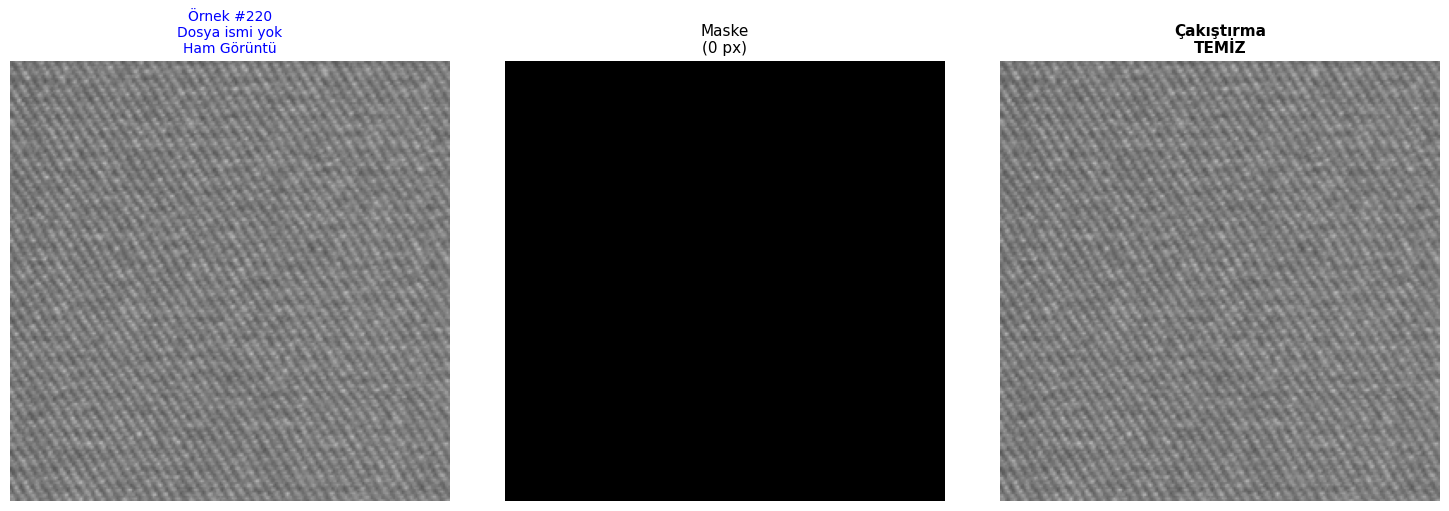

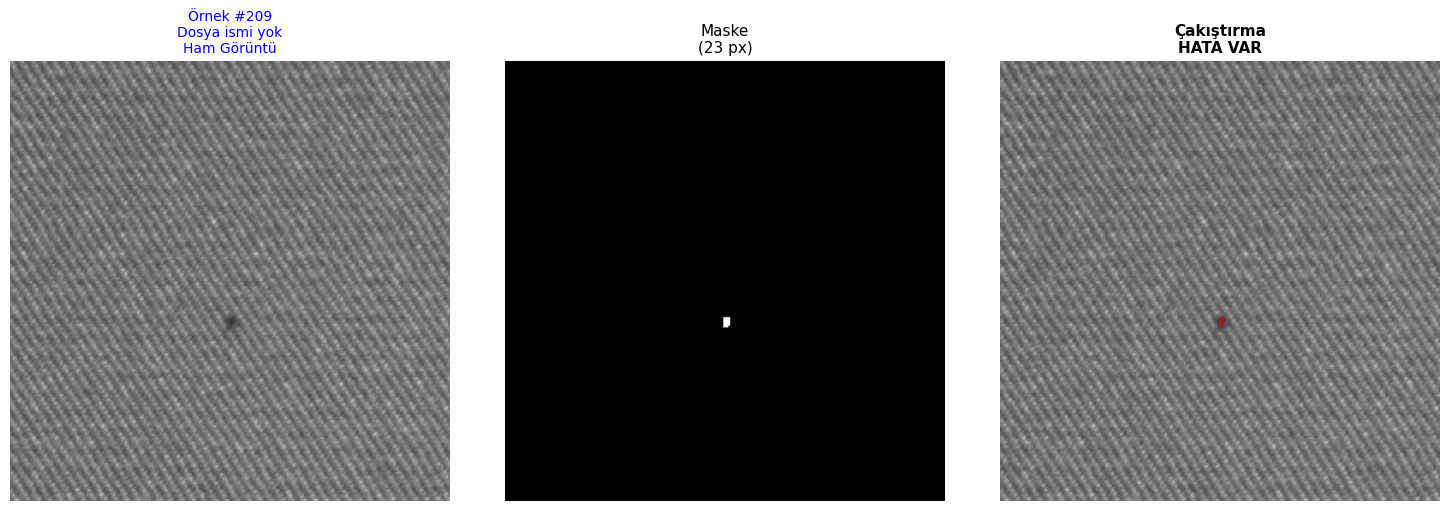

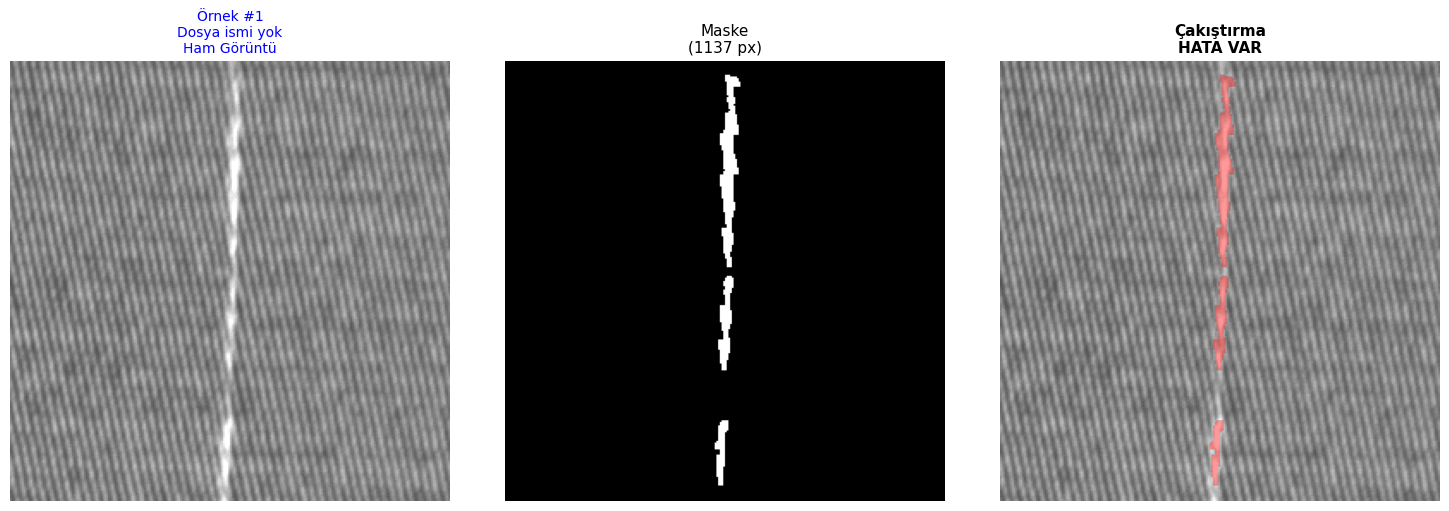

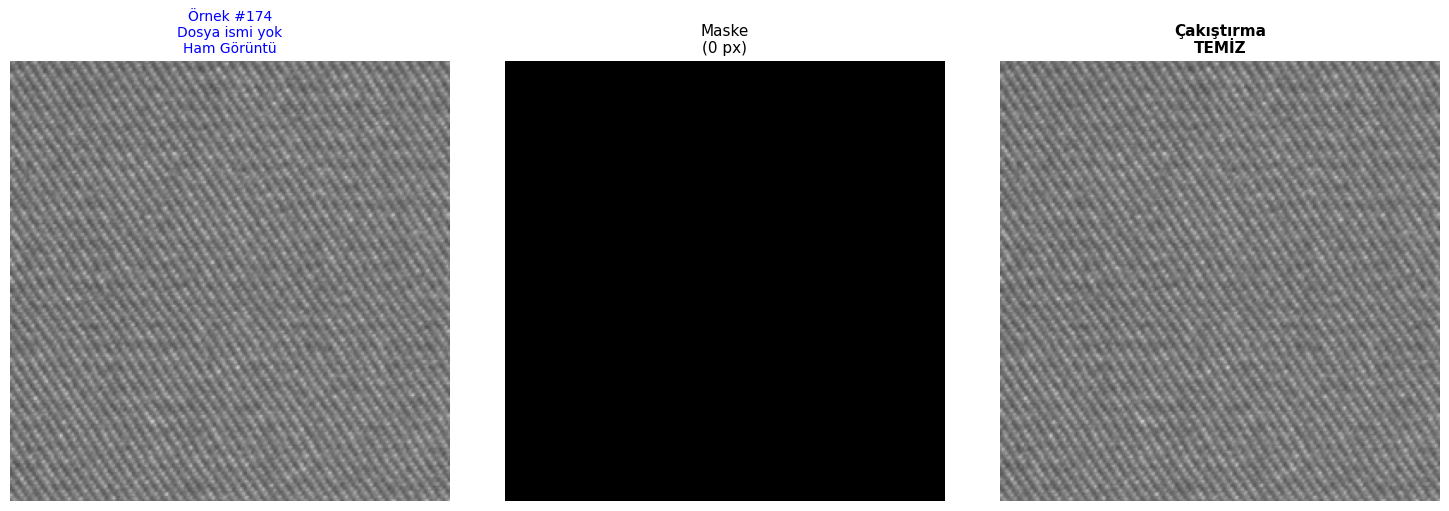

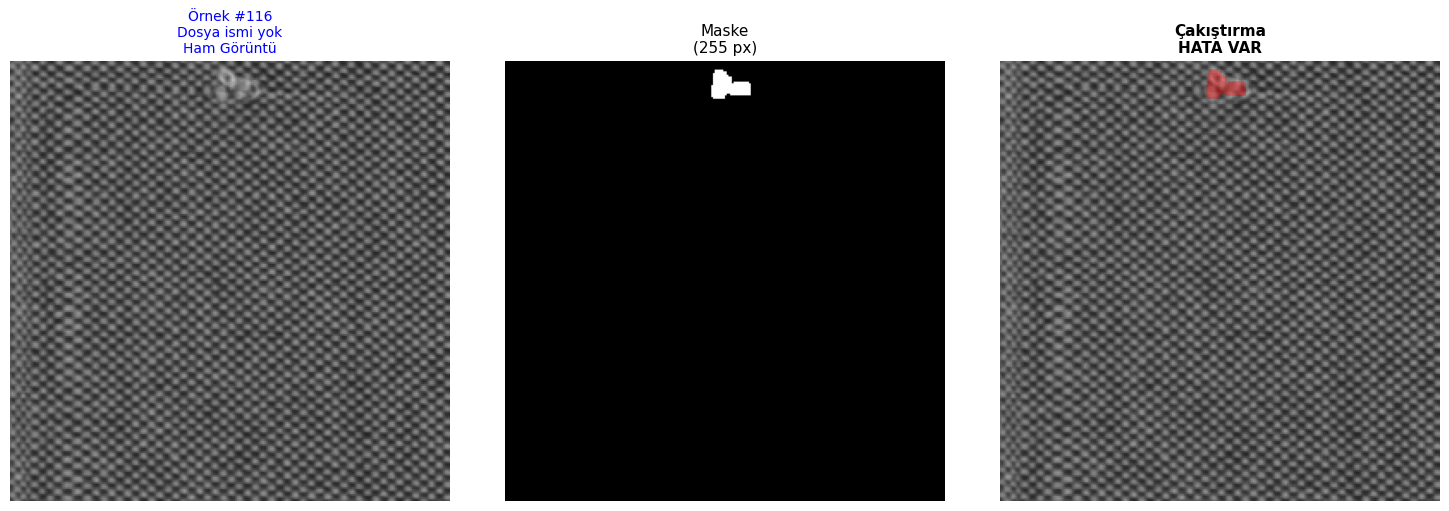

In [19]:
import matplotlib.pyplot as plt
import numpy as np

def simple_visualize(dataset, num_samples=5):
    """
    GÜNCELLENMİŞ VERSİYON:
    Dataset artık 3 değer döndürdüğü için (resim, maske, dosya_ismi)
    bu fonksiyon da ona göre güncellendi.
    """
    print(f"\n{'='*60}")
    print(f"DOĞAL GÖRÜNTÜLEME (DOSYA İSİMLİ) - {num_samples} ÖRNEK")
    print(f"{'='*60}")
    
    # Rastgele indexler seç
    if len(dataset) < num_samples:
        indices = range(len(dataset))
    else:
        indices = np.random.choice(len(dataset), num_samples, replace=False)
    
    for i, idx in enumerate(indices):
        # --- DÜZELTME BURADA ---
        # Artık 3 değer geliyor, üçünü de karşılıyoruz.
        # Eğer eski dataset sınıfı hafızadaysa ve 2 değer dönerse diye önlem alalım:
        data = dataset.get_item(idx)
        
        if len(data) == 3:
            image, mask, filename = data
        else:
            image, mask = data
            filename = "Dosya ismi yok"
        # -----------------------
        
        img_show = image[:, :, 0]
        mask_show = mask[:, :, 0]
        
        defect_pixels = np.sum(mask_show > 0)
        has_defect = defect_pixels > 0
        
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # 1. ORİJİNAL GÖRÜNTÜ
        axes[0].imshow(img_show, cmap='gray', vmin=0, vmax=1)
        # Başlığa dosya ismini de ekledik, kontrol için harika olur
        axes[0].set_title(f"Örnek #{idx}\n{filename}\nHam Görüntü", fontsize=10, color='blue')
        axes[0].axis('off')
        
        # 2. MASKE
        axes[1].imshow(mask_show, cmap='gray', vmin=0, vmax=1)
        axes[1].set_title(f"Maske\n({int(defect_pixels)} px)", fontsize=11)
        axes[1].axis('off')
        
        # 3. ÇAKIŞTIRMA
        axes[2].imshow(img_show, cmap='gray', vmin=0, vmax=1)
        if has_defect:
            overlay = np.zeros((img_show.shape[0], img_show.shape[1], 4))
            overlay[mask_show > 0] = [1, 0, 0, 0.4] 
            axes[2].imshow(overlay)
            status = "HATA VAR"
        else:
            status = "TEMİZ"
            
        axes[2].set_title(f"Çakıştırma\n{status}", fontsize=11, fontweight='bold')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()

# Şimdi tekrar çalıştırabilirsin
print("Validation Setinden Örnekler:")
simple_visualize(val_dataset_obj, num_samples=5)


EN ÇOK HATALI GÖRÜNEN 5 ÖRNEK (TEMİZLENMİŞ VERİ SETİNDEN):



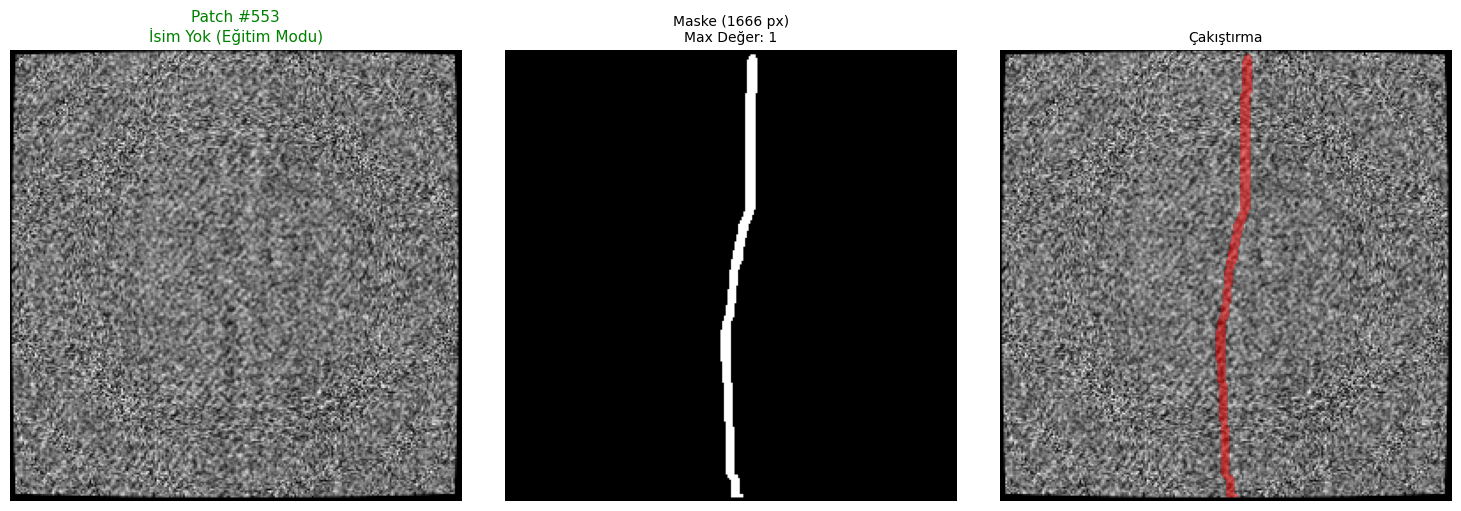

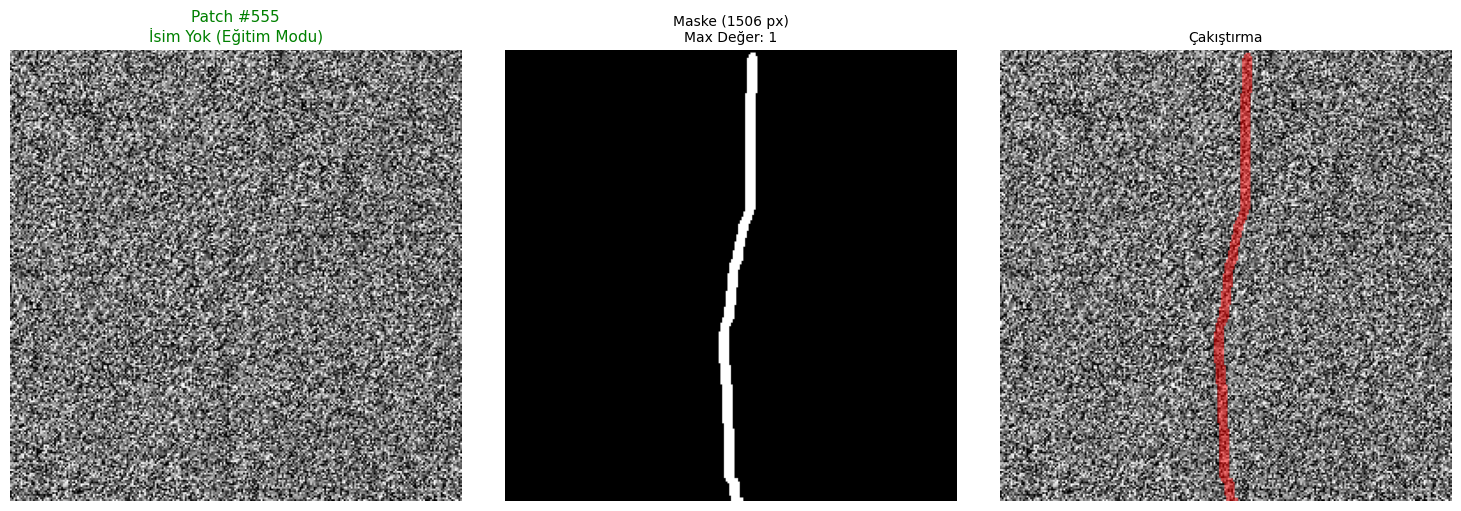

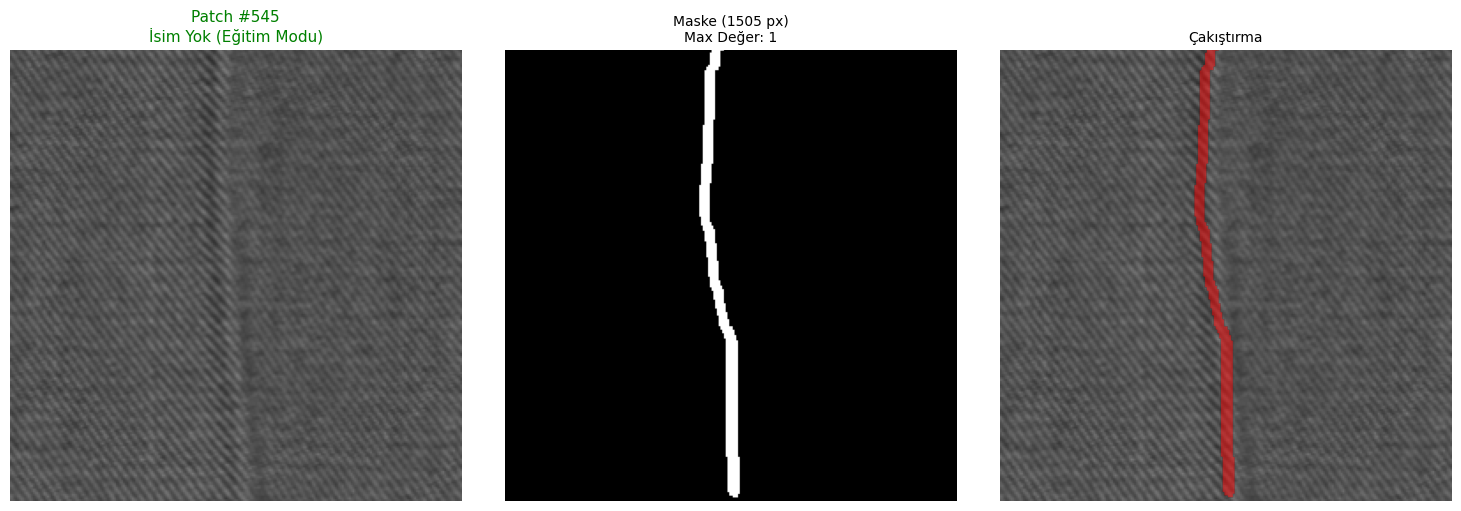

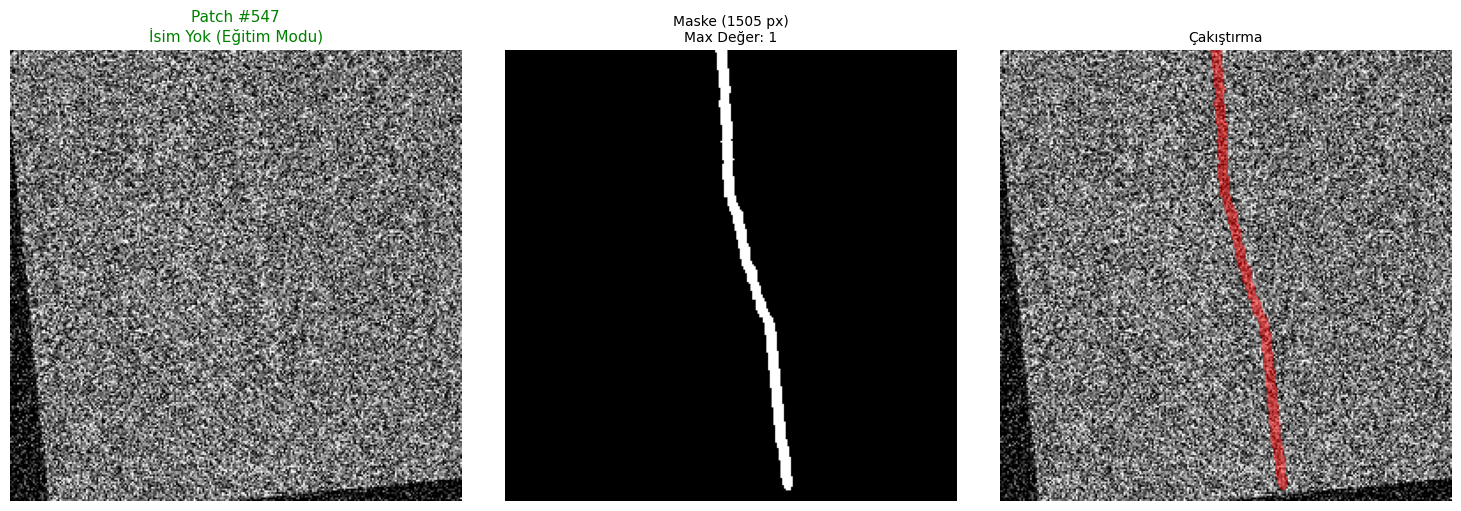

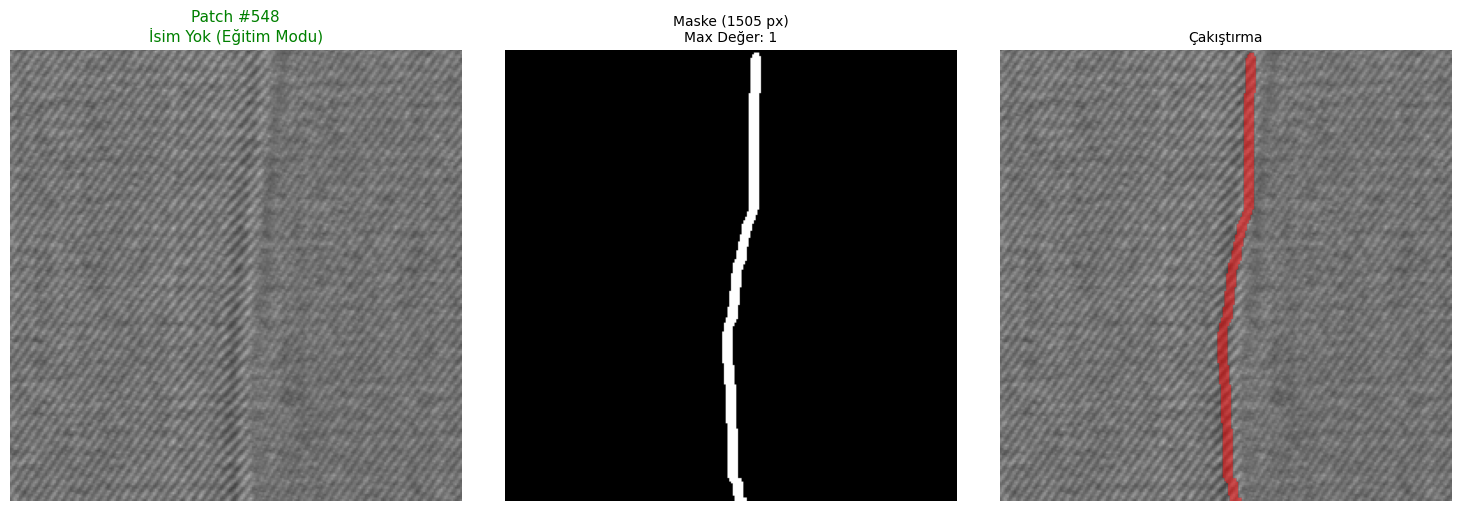

In [20]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_with_filename(dataset_obj, num_samples=5):
    """
    Bu fonksiyon artık hem 2'li (Eğitim Modu) hem 3'lü (Debug Modu) 
    dönüşleri destekler. Hata vermez.
    """
    defect_indices = [i for i, label in enumerate(dataset_obj.labels) if label == 1]
    if not defect_indices: 
        print("Dataset'te hiç hata (defect) kalmamış!")
        return
    
    # En çok hatalı olanları bul
    defect_counts = []
    for idx in defect_indices:
        # --- GÜVENLİ VERİ ALMA ---
        data = dataset_obj.get_item(idx)
        if len(data) == 3:
            _, mask, _ = data
        else:
            _, mask = data
            
        count = np.sum(mask > 0)
        defect_counts.append((idx, count))
    
    defect_counts.sort(key=lambda x: x[1], reverse=True)
    
    print(f"\nEN ÇOK HATALI GÖRÜNEN {num_samples} ÖRNEK (TEMİZLENMİŞ VERİ SETİNDEN):\n")
    
    for i in range(min(num_samples, len(defect_counts))):
        idx, count = defect_counts[i]
        
        # --- TEKRAR GÜVENLİ VERİ ALMA ---
        data = dataset_obj.get_item(idx)
        if len(data) == 3:
            img, mask, filename = data
        else:
            img, mask = data
            filename = "İsim Yok (Eğitim Modu)" # 2 değer döndüğü için isim elimizde yok
        
        # Grafik
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Resim
        axes[0].imshow(img[:,:,0], cmap='gray', vmin=0, vmax=1)
        axes[0].set_title(f"Patch #{idx}\n{filename}", fontsize=11, color='green')
        axes[0].axis('off')
        
        # Maske
        axes[1].imshow(mask[:,:,0], cmap='gray', vmin=0, vmax=1)
        axes[1].set_title(f"Maske ({count:.0f} px)\nMax Değer: {mask.max():.0f}", fontsize=10)
        axes[1].axis('off')
        
        # Çakıştırma
        axes[2].imshow(img[:,:,0], cmap='gray', vmin=0, vmax=1)
        overlay = np.zeros((256, 256, 4))
        overlay[mask[:,:,0] > 0] = [1, 0, 0, 0.5]
        axes[2].imshow(overlay)
        axes[2].set_title("Çakıştırma", fontsize=10)
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()

# Kodu Çalıştır
visualize_with_filename(train_dataset_obj, num_samples=5)

In [21]:
# Custom metrics for Keras
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

def bce_dice_loss(y_true, y_pred):
    # Hem binary cross entropy (genel dağılım) 
    # Hem de dice loss (kesişim başarısı) beraber kullanılır
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    dice = dice_loss(y_true, y_pred)
    return bce + dice
    
def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def recall_m(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    possible_positives = tf.reduce_sum(y_true_f)
    return true_positives / (possible_positives + 1e-6)

def precision_m(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    return true_positives / (predicted_positives + 1e-6)

def f1_m(y_true, y_pred):
    precision = precision_m(y_true, y_pred)
    recall = recall_m(y_true, y_pred)
    return 2*((precision*recall)/(precision+recall+1e-6))

In [22]:
# Veri Kontrolü
sample_img, sample_mask = train_dataset_obj.get_item(0)
print(f"Maske Min Değeri: {sample_mask.min()}")
print(f"Maske Max Değeri: {sample_mask.max()}")

if sample_mask.max() > 1.0:
    print("HATA: Maske hala 255 (veya büyük) değer içeriyor!")
else:
    print("BAŞARILI: Maske 0-1 aralığında.")

Maske Min Değeri: 0.0
Maske Max Değeri: 1.0
BAŞARILI: Maske 0-1 aralığında.



Training Attention U-Net model...
Epoch 1/200


I0000 00:00:1770299212.979828      74 service.cc:152] XLA service 0x7ac9c000c6a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1770299212.979877      74 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1770299212.979883      74 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1770299215.584613      74 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-02-05 13:47:03.035091: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng12{k11=2} for conv %cudnn-conv-bias-activation.138 = (f32[16,256,32,32]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,768,32,32]{3,2,1,0} %bitcast.50198, f32[256,768,3,3]{3,2,1,0} %bitcast.41208, f32[256]{0} %bitcast.50258), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="Attention_UNet_1/conv2d_13_1/convolutio

     70/Unknown 107s 476ms/step - accuracy: 0.9566 - dice_coef: 0.0046 - loss: 1.3383
Epoch 1: val_loss improved from inf to 1.23445, saving model to best_model.h5


70/70 ━━━━━━━━━━━━━━━━━━━━ 113s 565ms/step - accuracy: 0.9569 - dice_coef: 0.0046 - loss: 1.3374 - val_accuracy: 0.9970 - val_dice_coef: 0.0056 - val_loss: 1.2344 - learning_rate: 1.0000e-04
Epoch 2/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.9961 - dice_coef: 0.0051 - loss: 1.1705
Epoch 2: val_loss improved from 1.23445 to 1.18147, saving model to best_model.h5


70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 553ms/step - accuracy: 0.9961 - dice_coef: 0.0051 - loss: 1.1704 - val_accuracy: 0.9970 - val_dice_coef: 0.0056 - val_loss: 1.1815 - learning_rate: 1.0000e-04
Epoch 3/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9965 - dice_coef: 0.0055 - loss: 1.1375
Epoch 3: val_loss improved from 1.18147 to 1.14635, saving model to best_model.h5


...

70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 554ms/step - accuracy: 0.9978 - dice_coef: 0.4143 - loss: 0.5998 - val_accuracy: 0.9976 - val_dice_coef: 0.3858 - val_loss: 0.6291 - learning_rate: 1.0000e-04
Epoch 54/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9976 - dice_coef: 0.4387 - loss: 0.5767
Epoch 54: val_loss did not improve from 0.62907
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 547ms/step - accuracy: 0.9976 - dice_coef: 0.4388 - loss: 0.5765 - val_accuracy: 0.9974 - val_dice_coef: 0.3407 - val_loss: 0.6750 - learning_rate: 1.0000e-04
Epoch 55/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9978 - dice_coef: 0.4338 - loss: 0.5805
Epoch 55: val_loss did not improve from 0.62907
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 547ms/step - accuracy: 0.9978 - dice_coef: 0.4338 - loss: 0.5806 - val_accuracy: 0.9976 - val_dice_coef: 0.3333 - val_loss: 0.6818 - learning_rate: 1.0000e-04
Epoch 56/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9977 - dice_coef: 0.4526 - loss: 0.5622
Epoch 56: 

70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 555ms/step - accuracy: 0.9980 - dice_coef: 0.4756 - loss: 0.5387 - val_accuracy: 0.9978 - val_dice_coef: 0.3984 - val_loss: 0.6170 - learning_rate: 5.0000e-05
Epoch 66/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9978 - dice_coef: 0.4713 - loss: 0.5450
Epoch 66: val_loss did not improve from 0.61697
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 549ms/step - accuracy: 0.9978 - dice_coef: 0.4716 - loss: 0.5446 - val_accuracy: 0.9977 - val_dice_coef: 0.3527 - val_loss: 0.6631 - learning_rate: 5.0000e-05
Epoch 67/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9978 - dice_coef: 0.4438 - loss: 0.5720
Epoch 67: val_loss did not improve from 0.61697
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 548ms/step - accuracy: 0.9978 - dice_coef: 0.4445 - loss: 0.5713 - val_accuracy: 0.9977 - val_dice_coef: 0.3581 - val_loss: 0.6581 - learning_rate: 5.0000e-05
Epoch 68/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9979 - dice_coef: 0.4745 - loss: 0.5406
Epoch 68: 

70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 555ms/step - accuracy: 0.9979 - dice_coef: 0.4867 - loss: 0.5280 - val_accuracy: 0.9975 - val_dice_coef: 0.4111 - val_loss: 0.6055 - learning_rate: 5.0000e-05
Epoch 70/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9981 - dice_coef: 0.5142 - loss: 0.4994
Epoch 70: val_loss did not improve from 0.60555
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 549ms/step - accuracy: 0.9981 - dice_coef: 0.5142 - loss: 0.4995 - val_accuracy: 0.9977 - val_dice_coef: 0.3913 - val_loss: 0.6247 - learning_rate: 5.0000e-05
Epoch 71/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9980 - dice_coef: 0.5301 - loss: 0.4844
Epoch 71: val_loss did not improve from 0.60555
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 548ms/step - accuracy: 0.9980 - dice_coef: 0.5300 - loss: 0.4845 - val_accuracy: 0.9975 - val_dice_coef: 0.3682 - val_loss: 0.6491 - learning_rate: 5.0000e-05
Epoch 72/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9980 - dice_coef: 0.4972 - loss: 0.5172
Epoch 72: 

70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 555ms/step - accuracy: 0.9981 - dice_coef: 0.5083 - loss: 0.5063 - val_accuracy: 0.9977 - val_dice_coef: 0.4140 - val_loss: 0.6025 - learning_rate: 2.5000e-05
Epoch 82/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9982 - dice_coef: 0.5226 - loss: 0.4906
Epoch 82: val_loss did not improve from 0.60253
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 546ms/step - accuracy: 0.9982 - dice_coef: 0.5228 - loss: 0.4904 - val_accuracy: 0.9977 - val_dice_coef: 0.3925 - val_loss: 0.6243 - learning_rate: 2.5000e-05
Epoch 83/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9980 - dice_coef: 0.5566 - loss: 0.4582
Epoch 83: val_loss did not improve from 0.60253
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 547ms/step - accuracy: 0.9980 - dice_coef: 0.5566 - loss: 0.4582 - val_accuracy: 0.9977 - val_dice_coef: 0.3640 - val_loss: 0.6532 - learning_rate: 2.5000e-05
Epoch 84/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9981 - dice_coef: 0.5439 - loss: 0.4702
Epoch 84: 

70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 555ms/step - accuracy: 0.9983 - dice_coef: 0.5311 - loss: 0.4821 - val_accuracy: 0.9977 - val_dice_coef: 0.4183 - val_loss: 0.5990 - learning_rate: 6.2500e-06
Epoch 104/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9980 - dice_coef: 0.5544 - loss: 0.4609
Epoch 104: val_loss did not improve from 0.59896
70/70 ━━━━━━━━━━━━━━━━━━━━ 44s 547ms/step - accuracy: 0.9981 - dice_coef: 0.5545 - loss: 0.4607 - val_accuracy: 0.9977 - val_dice_coef: 0.4061 - val_loss: 0.6113 - learning_rate: 6.2500e-06
Epoch 105/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.9985 - dice_coef: 0.6029 - loss: 0.4087
Epoch 105: val_loss did not improve from 0.59896
70/70 ━━━━━━━━━━━━━━━━━━━━ 43s 545ms/step - accuracy: 0.9985 - dice_coef: 0.6027 - loss: 0.4090 - val_accuracy: 0.9977 - val_dice_coef: 0.4074 - val_loss: 0.6101 - learning_rate: 6.2500e-06
Epoch 106/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9984 - dice_coef: 0.5491 - loss: 0.4630
Epoch

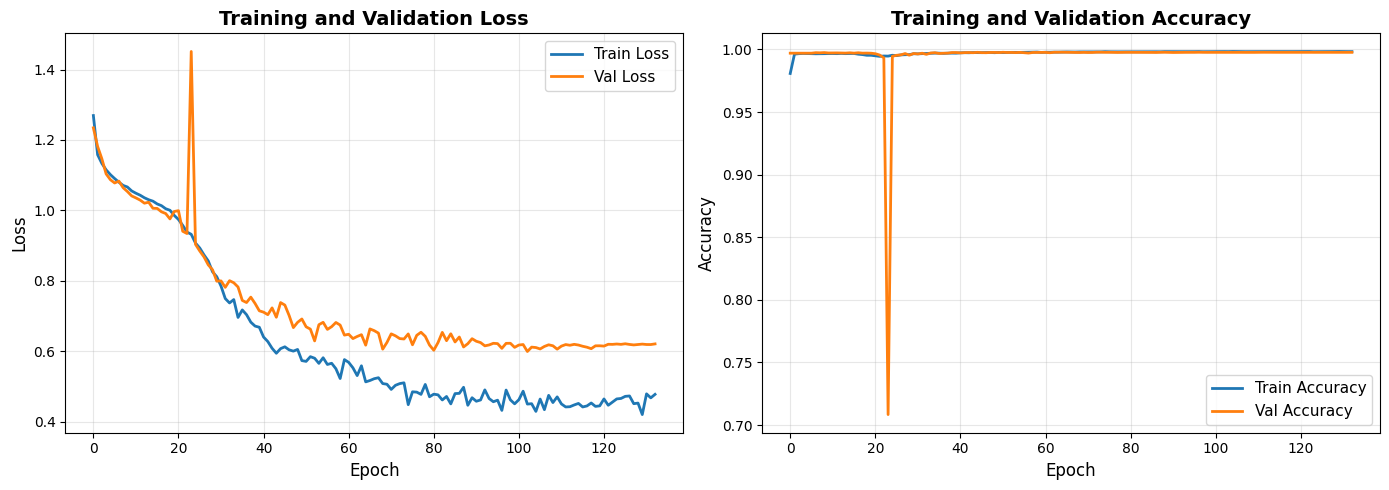


Plotting HRNet training history...


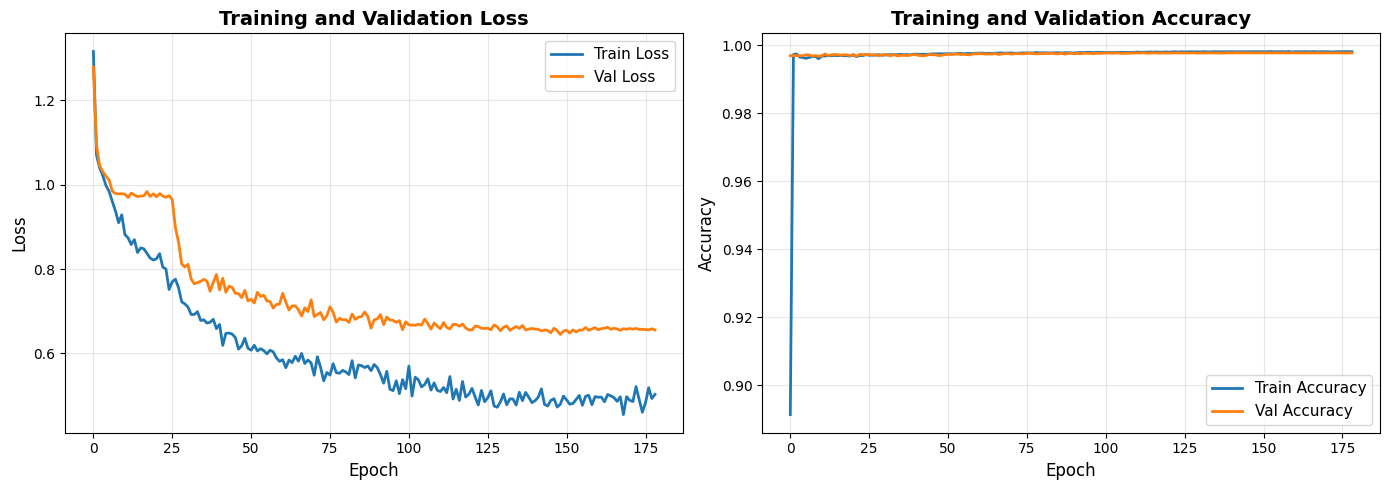


Evaluating Attention U-Net model...

MULTI-THRESHOLD EVALUATION
Generating predictions...

Threshold   Dice      IoU       Recall    Precision F1        
----------------------------------------------------------------------
0.10        0.6109    0.4398    0.6150    0.6068    0.6109    
0.20        0.6097    0.4385    0.6029    0.6167    0.6097    
0.30        0.6082    0.4370    0.5946    0.6225    0.6082    
0.40        0.6064    0.4351    0.5872    0.6269    0.6064    
0.50        0.6046    0.4333    0.5806    0.6308    0.6046    
0.60        0.6028    0.4314    0.5742    0.6345    0.6028    
0.70        0.6011    0.4297    0.5670    0.6395    0.6011    

BEST THRESHOLD: 0.10
  Dice: 0.6109
  IoU: 0.4398
  Recall: 0.6150
  Precision: 0.6068
  F1: 0.6109



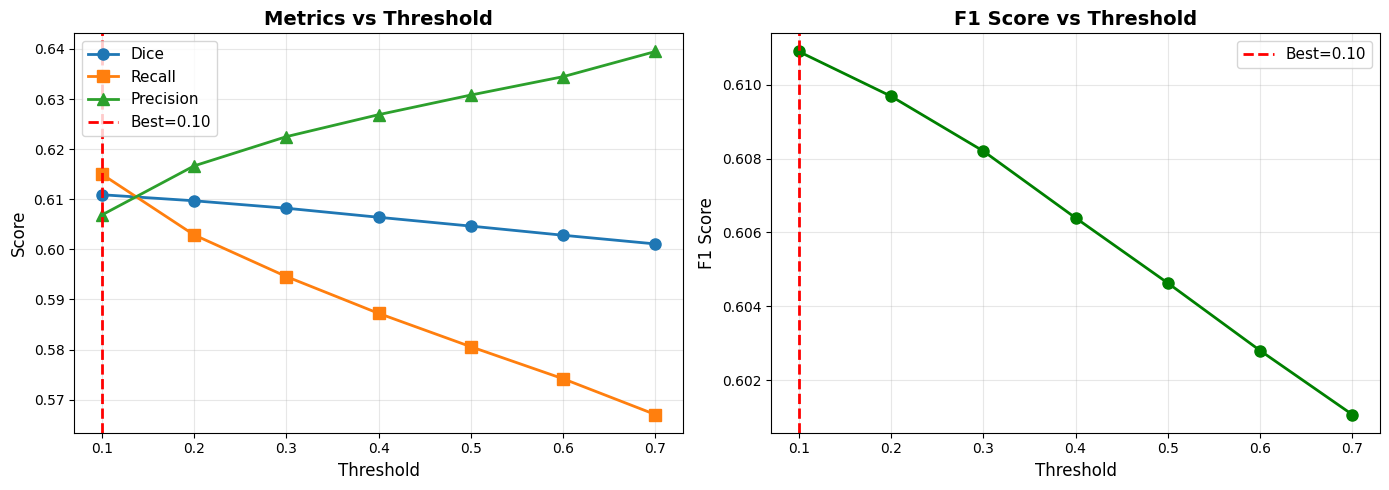


Evaluating HRNet model...

MULTI-THRESHOLD EVALUATION
Generating predictions...

Threshold   Dice      IoU       Recall    Precision F1        
----------------------------------------------------------------------
0.10        0.6004    0.4290    0.5936    0.6075    0.6004    
0.20        0.5975    0.4260    0.5657    0.6330    0.5975    
0.30        0.5942    0.4227    0.5466    0.6507    0.5942    
0.40        0.5888    0.4172    0.5288    0.6641    0.5888    
0.50        0.5831    0.4115    0.5115    0.6779    0.5831    
0.60        0.5762    0.4047    0.4940    0.6913    0.5762    
0.70        0.5669    0.3955    0.4738    0.7054    0.5669    

BEST THRESHOLD: 0.10
  Dice: 0.6004
  IoU: 0.4290
  Recall: 0.5936
  Precision: 0.6075
  F1: 0.6004



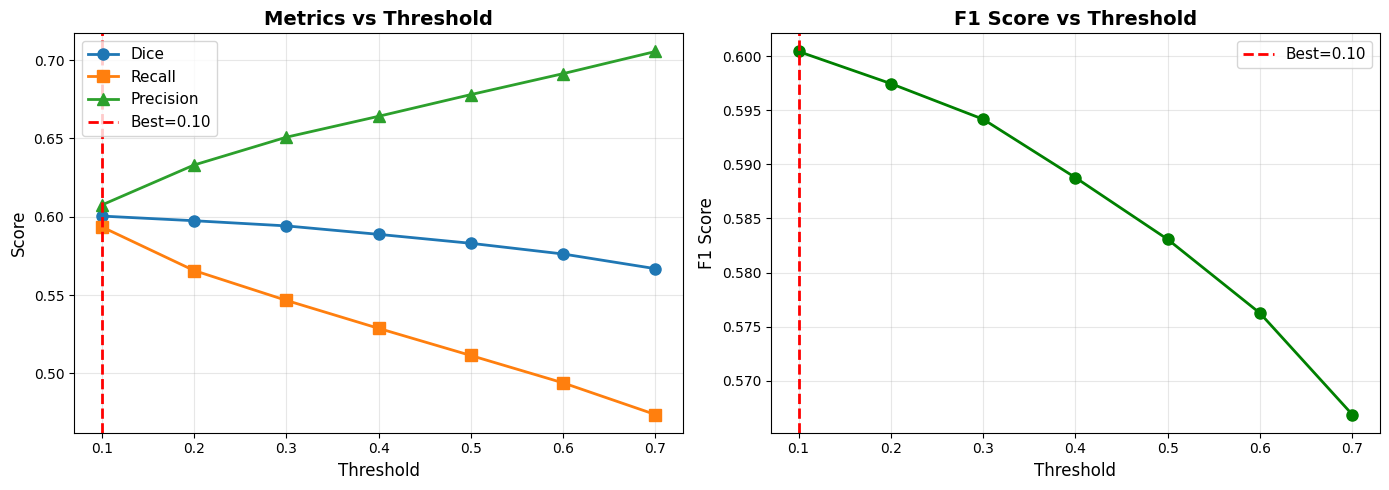


Attention U-Net Best Metrics: {'dice': np.float32(0.61089605), 'iou': np.float32(0.43977702), 'recall': np.float32(0.61499727), 'precision': np.float32(0.6068491), 'f1': np.float32(0.61089593), 'tp': 32978, 'fp': 21365, 'fn': 20645, 'tn': 17750808}
HRNet Best Metrics: {'dice': np.float32(0.60043955), 'iou': np.float32(0.42902008), 'recall': np.float32(0.59356993), 'precision': np.float32(0.60747004), 'f1': np.float32(0.6004394), 'tp': 31829, 'fp': 20567, 'fn': 21794, 'tn': 17751604}


In [23]:
# Example: Training and comparing Attention U-Net and HRNet

# Build datasets
# (Assume train_dataset and val_dataset are already created as in your pipeline)

# Build models
attention_unet_model = build_attention_unet(input_shape=(256, 256, 1), filters_base=32)
hrnet_model = build_hrnet(input_shape=(Config.PATCH_SIZE, Config.PATCH_SIZE, 1), base_filters=32)

# Compile models
attention_unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,           
    metrics=['accuracy', dice_coef] 
)

hrnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=Config.LEARNING_RATE),
    loss=bce_dice_loss,          
    metrics=['accuracy', dice_coef]
)


# Train Attention U-Net
print("\nTraining Attention U-Net model...")
history_attention_unet = attention_unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

# Train HRNet
print("\nTraining HRNet model...")
history_hrnet = hrnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

# Plot training histories
print("\nPlotting Attention U-Net training history...")
plot_training_history(history_attention_unet)
print("\nPlotting HRNet training history...")
plot_training_history(history_hrnet)

# Evaluate and compare
print("\nEvaluating Attention U-Net model...")
best_thresh_unet, best_metrics_unet = multi_threshold_evaluation(attention_unet_model, val_dataset)
print("\nEvaluating HRNet model...")
best_thresh_hrnet, best_metrics_hrnet = multi_threshold_evaluation(hrnet_model, val_dataset)

print("\nAttention U-Net Best Metrics:", best_metrics_unet)
print("HRNet Best Metrics:", best_metrics_hrnet)

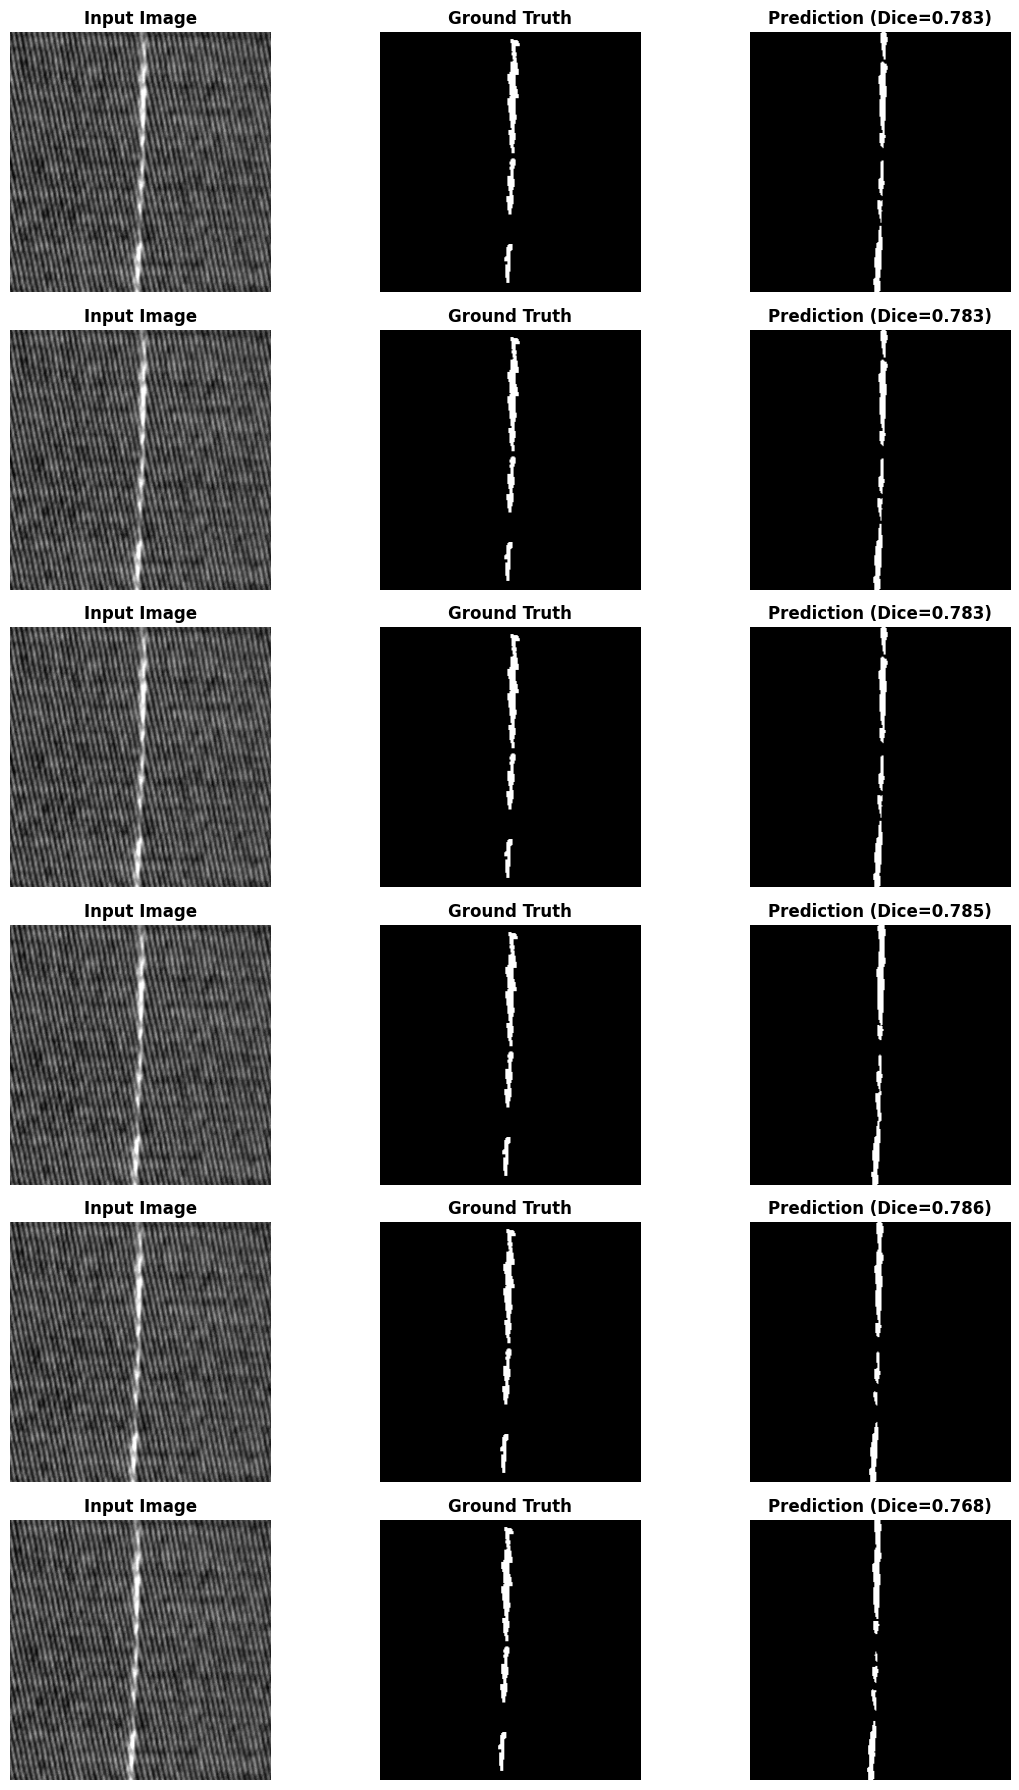

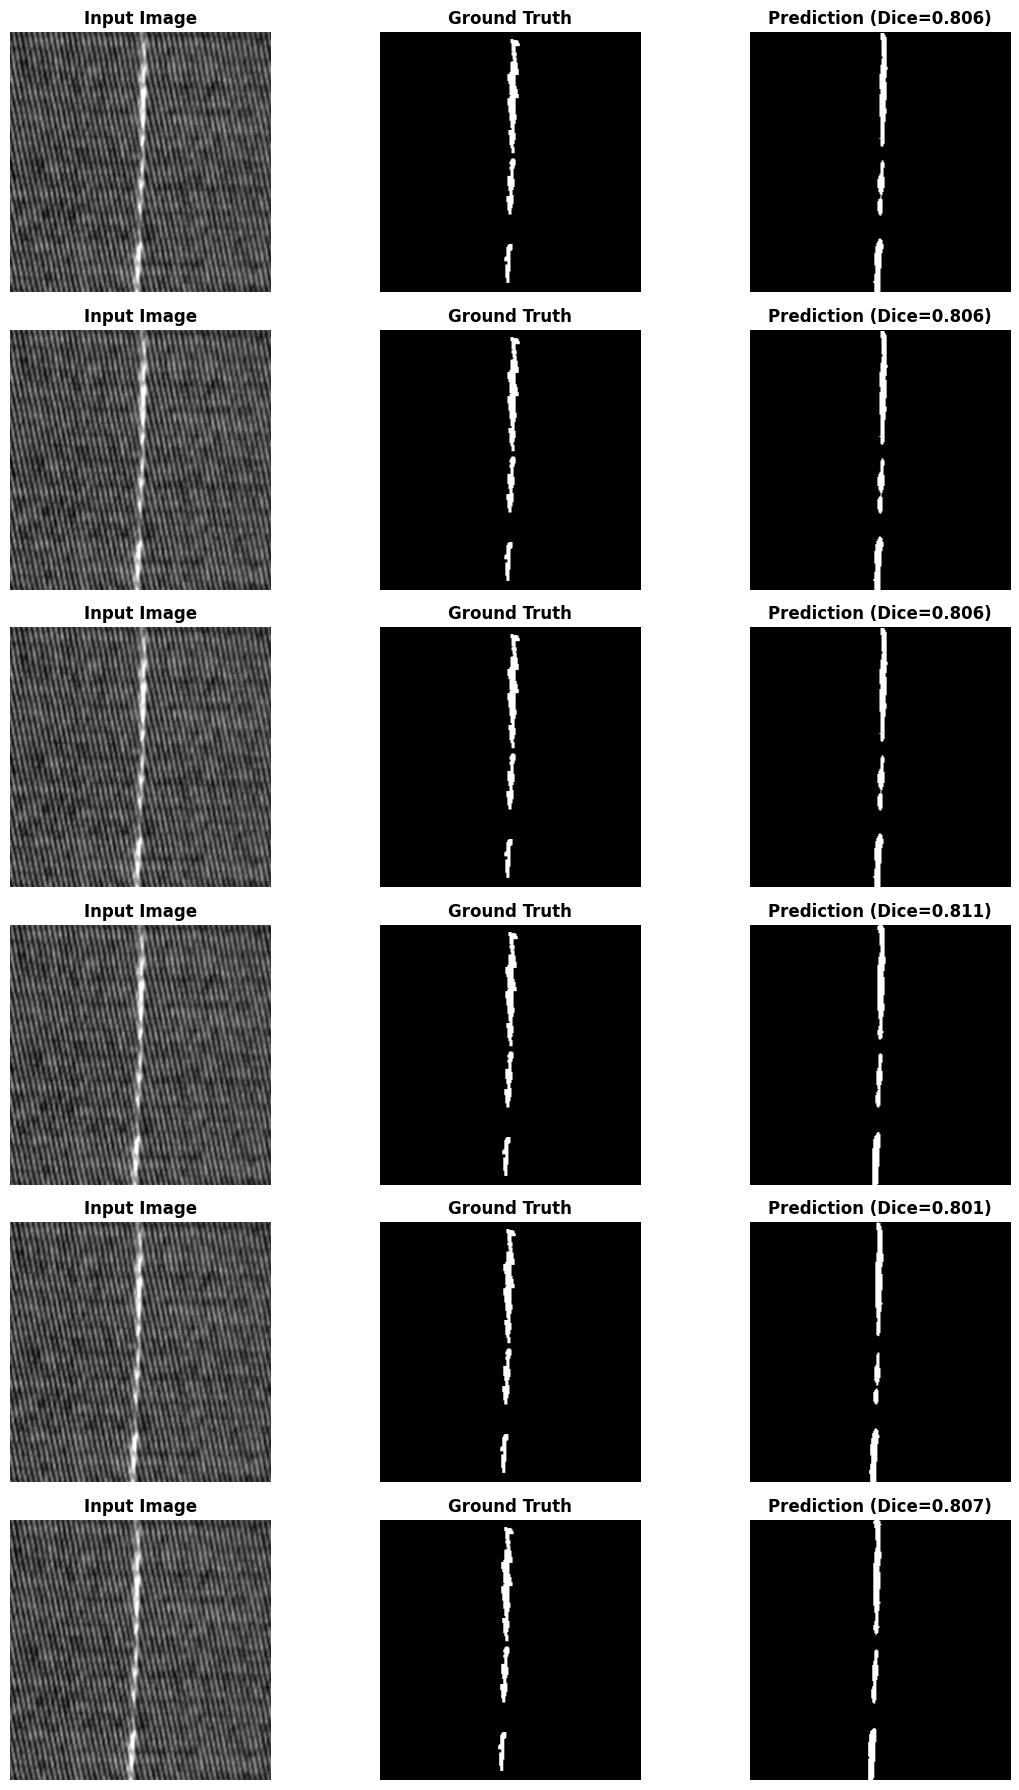

In [24]:
visualize_predictions(attention_unet_model, val_dataset, num_samples=6, threshold=best_thresh_unet)
visualize_predictions(hrnet_model, val_dataset, num_samples=6, threshold=best_thresh_hrnet)

In [25]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import shutil

def save_prediction_results(model, dataset_obj, output_folder="Model_Sonuclari", num_samples=20, threshold=0.5):
    """
    Model tahminlerini görselleştirir ve klasöre kaydeder.
    """
    # 1. Klasör Yapısını Oluştur
    plot_dir = os.path.join(output_folder, "karsilastirma_tablolari")
    mask_dir = os.path.join(output_folder, "saf_tahmin_maskeleri")
    
    os.makedirs(plot_dir, exist_ok=True)
    os.makedirs(mask_dir, exist_ok=True)
    
    print(f"💾 Kayıt İşlemi Başladı... Hedef Klasör: {output_folder}")
    
    count_saved = 0
    
    # 2. Döngü
    for i in range(min(num_samples, len(dataset_obj))):
        # Veriyi al
        img, true_mask = dataset_obj.get_item(i)
        
        # Model Tahmini
        input_img = np.expand_dims(img, axis=0)
        pred_prob = model.predict(input_img, verbose=0)[0] # Olasılık haritası (0.0 - 1.0)
        
        # Binary Maske (Eşiklenmiş - 0 veya 1)
        pred_binary = (pred_prob > threshold).astype(np.float32)
        
        # --- A) KARŞILAŞTIRMA GRAFİĞİNİ KAYDET ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Orijinal
        axes[0].imshow(img[:,:,0], cmap='gray')
        axes[0].set_title(f"Örnek #{i} - Orijinal")
        axes[0].axis('off')
        
        # Gerçek Maske
        axes[1].imshow(true_mask[:,:,0], cmap='gray', vmin=0, vmax=1)
        axes[1].set_title("Gerçek Maske (Ground Truth)")
        axes[1].axis('off')
        
        # Model Tahmini (Renkli Olasılık)
        # Olasılıkları görelim ki modelin ne kadar emin olduğunu anlayalım
        axes[2].imshow(pred_prob[:,:,0], cmap='inferno', vmin=0, vmax=1) 
        axes[2].set_title(f"Model Tahmini\n(Max Güven: {pred_prob.max():.2f})")
        axes[2].axis('off')
        
        # Grafiği Kaydet
        plot_path = os.path.join(plot_dir, f"result_{i:03d}_plot.png")
        plt.savefig(plot_path, bbox_inches='tight')
        plt.close(fig) # Hafızayı şişirmemek için kapat
        
        # --- B) SAF MASKEYİ KAYDET (PNG) ---
        # 0-1 arası değeri 0-255 yapıp kaydediyoruz
        mask_path = os.path.join(mask_dir, f"result_{i:03d}_mask.png")
        cv2.imwrite(mask_path, (pred_binary * 255).astype(np.uint8))
        
        count_saved += 1
        if (i+1) % 10 == 0:
            print(f"   -> {i+1} adet görsel işlendi...")

    print(f"\n✅ İŞLEM TAMAM! Toplam {count_saved} görsel '{output_folder}' içine kaydedildi.")
    
    # 3. Klasörü İndirmek İçin Zip Yap (Kaggle/Colab için çok yararlı)
    shutil.make_archive(output_folder, 'zip', output_folder)
    print(f"📦 '{output_folder}.zip' dosyası oluşturuldu. İndirebilirsiniz!")

# --- KULLANIM ---
# Hangi modeli ve dataseti kullanmak istiyorsan buraya yaz
# Öneri: Validation setini kullan ki modelin görmediği verideki başarısını gör.

save_prediction_results(
    model=attention_unet_model,       # Eğittiğin model ismi
    dataset_obj=val_dataset_obj,      # Validation datasetin
    output_folder="AITex_Sonuclar",   # Klasör ismi
    num_samples=50,                   # Kaç resim kaydedilsin?
    threshold=0.5                     # Hangi değerin üstü hata sayılsın?
)

💾 Kayıt İşlemi Başladı... Hedef Klasör: AITex_Sonuclar


2026-02-05 17:28:22.842240: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-05 17:28:23.074840: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


   -> 10 adet görsel işlendi...
   -> 20 adet görsel işlendi...
   -> 30 adet görsel işlendi...
   -> 40 adet görsel işlendi...
   -> 50 adet görsel işlendi...

✅ İŞLEM TAMAM! Toplam 50 görsel 'AITex_Sonuclar' içine kaydedildi.
📦 'AITex_Sonuclar.zip' dosyası oluşturuldu. İndirebilirsiniz!


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def save_training_metrics(history, model_name="Model", output_folder="Model_Metrikleri"):
    """
    Eğitim geçmişini (history) CSV olarak kaydeder ve grafiklerini çizer.
    """
    # 1. Klasörü Oluştur
    os.makedirs(output_folder, exist_ok=True)
    print(f"📊 Metrik Kaydı Başladı... Hedef: {output_folder}")
    
    # 2. Verileri DataFrame'e Çevir ve Kaydet (Excel/CSV)
    # history.history bir sözlüktür, bunu tabloya çeviriyoruz
    df = pd.DataFrame(history.history)
    
    # En iyi epoch'u bul (Dice skoruna göre)
    if 'val_dice_coef' in df.columns:
        best_epoch = df['val_dice_coef'].idxmax()
        print(f"   🌟 En İyi Epoch: {best_epoch + 1} (Val Dice: {df.loc[best_epoch, 'val_dice_coef']:.4f})")
    
    # CSV Dosyası Olarak Kaydet
    csv_path = os.path.join(output_folder, f"{model_name}_training_log.csv")
    df.to_csv(csv_path, index_label="Epoch")
    print(f"   💾 Tablo kaydedildi: {csv_path}")
    
    # 3. Grafikleri Çiz ve Kaydet
    metrics_to_plot = [
        ('loss', 'val_loss', 'Loss (Kayıp) Grafiği', 'min'),
        ('dice_coef', 'val_dice_coef', 'Dice Skoru (Başarı)', 'max'),
        ('accuracy', 'val_accuracy', 'Accuracy (Doğruluk)', 'max')
    ]
    
    plt.figure(figsize=(18, 5))
    
    for i, (train_metric, val_metric, title, mode) in enumerate(metrics_to_plot):
        if train_metric not in df.columns: continue
        
        plt.subplot(1, 3, i+1)
        plt.plot(df[train_metric], label=f'Eğitim {train_metric}', linewidth=2)
        plt.plot(df[val_metric], label=f'Doğrulama {val_metric}', linewidth=2, linestyle='--')
        
        # En iyi noktayı işaretle
        if mode == 'min':
            best_idx = df[val_metric].idxmin()
            best_val = df[val_metric].min()
            color = 'red'
        else:
            best_idx = df[val_metric].idxmax()
            best_val = df[val_metric].max()
            color = 'green'
            
        plt.scatter(best_idx, best_val, c=color, s=100, zorder=5, label=f'En İyi: {best_val:.4f}')
        
        plt.title(f"{model_name} - {title}")
        plt.xlabel("Epoch")
        plt.ylabel("Değer")
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    # Grafiği Kaydet
    plot_path = os.path.join(output_folder, f"{model_name}_metrics_plot.png")
    plt.savefig(plot_path, bbox_inches='tight')
    plt.close()
    print(f"   📈 Grafik kaydedildi: {plot_path}")
    print("-" * 50)

# --- KULLANIM ---

# 1. Attention U-Net için Kaydet (Eğitim değişkenin adı 'history_unet' ise)
# Eğer değişken adın farklıysa (örneğin sadece 'history') onu yaz.
if 'history_unet' in globals():
    save_training_metrics(history_unet, model_name="Attention_UNet")
elif 'history' in globals(): # Genelde sadece history kullanılır
    save_training_metrics(history, model_name="Attention_UNet")
else:
    print("⚠️ 'history' değişkeni bulunamadı. Eğitimi 'history = model.fit(...)' şeklinde başlattığından emin ol.")

# 2. HRNet için Kaydet (Varsa)
if 'history_hrnet' in globals():
    save_training_metrics(history_hrnet, model_name="HRNet")

# 3. Tüm dosyaları indirmek için zip yap
import shutil
shutil.make_archive("Model_Metrikleri", 'zip', "Model_Metrikleri")
print("\n📦 'Model_Metrikleri.zip' hazır! İndirebilirsin.")

⚠️ 'history' değişkeni bulunamadı. Eğitimi 'history = model.fit(...)' şeklinde başlattığından emin ol.
📊 Metrik Kaydı Başladı... Hedef: Model_Metrikleri
   🌟 En İyi Epoch: 149 (Val Dice: 0.3691)
   💾 Tablo kaydedildi: Model_Metrikleri/HRNet_training_log.csv
   📈 Grafik kaydedildi: Model_Metrikleri/HRNet_metrics_plot.png
--------------------------------------------------

📦 'Model_Metrikleri.zip' hazır! İndirebilirsin.
